In [ ]:
# Purpose:
#   Construct and validate an NHB-BC “upregulated” pseudobulk signature, then
#   characterize its biology and per-celltype expression.
#
# Steps
#   A) Define an NHB-BC Up gene list from pseudobulk DE results (BC stage, NHB vs NHW),
#      using a donor-level Mann–Whitney screen on normalized expression to ensure
#      NHB > NHW in BC.
#   B) Annotate genes (protein-coding vs others) via mygene and write GMT signatures.
#   C) Visualize:
#        1) Per-gene boxplots across race-stage groups (HRL/DCIS/BC × NHW/NHB)
#        2) Stacked bar: how many signature genes are DE (up) per celltype × disease stage
#        3) Enrichr pathway enrichment for the signature gene list + barplot top terms
#        4) ssGSEA score distributions across race-stage per celltype (boxplots)

# Header

In [1]:
from utils import *

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import scanpy as sc
import anndata as ad
import math
from collections import Counter
import pickle as pkl
import os 
from scipy.stats import linregress
import seaborn as sns

import gseapy as gp
from gseapy import barplot, dotplot

In [2]:
sc.settings.set_figure_params(dpi=600, dpi_save=600)  # 600 dpi for publication
sc.settings.figdir = "plots/Figure1"

rcParams.update({
    'font.family': 'Arial',
    'svg.fonttype': 'none', # Keeps text as font
    
    'font.size': 6,  # 5–7 pt as per guidelines
    'axes.titlesize': 7,
    'axes.labelsize': 6,
    'ytick.labelsize': 5,

    'legend.fontsize': 6,
    'legend.title_fontsize': 6,
    
    'figure.dpi': 600
})

plt.rcParams['axes.grid'] = False   # <--- turn off all grids globally
sns.set_style("white")              # <--- turn off seaborn grids

In [3]:
def read_gmt(file_path):
    gene_sets = {}
    with open(file_path, 'r') as f:
        for line in f:
            entries = line.strip().split('\t')
            gene_set_name = entries[0]
            description = entries[1]
            genes = entries[2:]
            gene_sets[gene_set_name] = {
                'description': description,
                'genes': genes
            }
    return gene_sets

In [4]:
os.chdir('../')

In [5]:
cells_group = {
    'B':['Naive B',
 'Mature B',
 'Memory B',
 'Plasmablast'],
    'T':['Naive CD4T',
 'Central Memory CD4T',
 'Effector Memory CD4T',
 'Cytotoxic CD4T',
 'Treg',
 'Naive CD8T',
 'Central Memory CD8T',
 'Effector Memory CD8T',
 'Double Negative T',
 'γδ T',
 'MAIT'],
    'DC':[
   'cDC1',
 'cDC2',
 'pDC'     
    ],
    'Mono':[
        'Classical Monocyte',
 'Intermediate Monocyte',
 'Nonclassical Monocyte',
 'Cytotoxic Monocyte'
        ],
    'NK':[
        'CD56-dim NK',
 'CD56-bright NK',
 'Proliferating NK'
    ]
}
major_celltype_palette = {
    'B':    '#3072C4',
    'T':    '#EF763F',
    'DC':   '#35A293',
    'Mono': '#B3813E',
    'NK':   '#7D4C99'
}

In [6]:
palette_meta = {
    'NHW-HRL':'#3194CC',
    'NHW-DCIS':'#825CA6',
    'NHW-BC':'#06948E',
    
    'NHB-HRL':'#F2B342',
    'NHB-DCIS':'#F472B6',
    'NHB-BC':'#C03830',

    'Diabetes':'navy',
    'Obesity':'salmon'
}


# Load data

In [8]:
import mygene

In [9]:
dat = ad.read_h5ad('data/03_cleandata/ft_all.h5ad')
print(len(dat.obs['dataset_name'].unique()))
dat

55


AnnData object with n_obs × n_vars = 434565 × 27879
    obs: 'nFeaturess_RNA', 'nFeaturess_RNA_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'doublets_score', 'nCount_RNA', 'nFeature_RNA', 'percent.mt', 'predicted.celltype.l1.score', 'predicted.celltype.l1', 'predicted.celltype.l2.score', 'predicted.celltype.l2', 'predicted.celltype.l3.score', 'predicted.celltype.l3', 'mapping.score', 'RNA_snn_res.0.8', 'seurat_clusters', 'dataset_name', 'RNA_snn_res.0.1', 'S.Score', 'G2M.Score', 'Phase', 'celltype_level3'
    var: 'vf_vst_counts.Pool137_10_mean', 'vf_vst_counts.Pool137_10_variance', 'vf_vst_counts.Pool137_10_variance.expected', 'vf_vst_counts.Pool137_10_variance.standardized', 'vf_vst_counts.Pool137_10_variable', 'vf_vst_counts.Pool137_10_rank', 'vf_vst_counts.Pool137_11_mean', 'vf_vst_counts.Pool137_11_variance', 'vf_vst_counts.Pool137_11_variance.expected', 'vf_vst_counts.Pool137_11_variance.standardized', 'vf_vst_counts.Pool137_11_variable', 'vf_vst_counts.Pool137

In [70]:
meta = pd.read_csv('data/01_meta/meta_pt.csv', 
                   index_col = 'dataset_name')

meta.index = [x.replace('_','-') for x in meta.index]

meta['race-stage'] = meta['race'].astype(str) + '-' + meta['group'].astype(str)

meta['race-stage'] = pd.Categorical(
    meta['race-stage'],
    categories=['NHW-HRL','NHB-HRL',  'NHW-DCIS','NHB-DCIS',  'NHW-BC','NHB-BC'],
    ordered=True
    )


meta

,sampleid,batch,viability_pct,group,race,age,diabetes,obesity,race-stage
Pool137-7,9-D,1,95,DCIS,NHW,37.0,N,N,NHW-DCIS
Pool137-12,30-D,1,92,DCIS,NHW,78.0,N,N,NHW-DCIS
Pool137-18,36-D,1,93,DCIS,NHB,39.0,N,N,NHB-DCIS
Pool137-20,119-D,1,95,DCIS,NHB,80.0,N,N,NHB-DCIS
Pool137-24,28-D,1,94,DCIS,NHW,53.0,N,N,NHW-DCIS
Pool137-27,53-D,1,96,DCIS,NHB,45.0,N,N,NHB-DCIS
Pool137-30,77-D,1,90,DCIS,NHW,45.0,N,N,NHW-DCIS
Pool138-6,31-D,2,93,DCIS,NHW,44.0,N,N,NHW-DCIS
Pool137-6,6-H,1,94,HRL,NHW,71.1,N,Y,NHW-HRL
Pool137-10,1-H,1,88,HRL,NHW,62.3,N,N,NHW-HRL


In [68]:
expr = pd.read_csv(
    'data/06_pb/pb_donor_normalizedexpression.csv',
    index_col=0
)

print(expr.shape)

expr

(27879, 55)


,Pool137-10,Pool137-11,Pool137-12,Pool137-14,Pool137-15,Pool137-16,Pool137-17,Pool137-18,Pool137-19,Pool137-20,...,Pool138-26,Pool138-27,Pool138-29,Pool138-3,Pool138-4,Pool138-5,Pool138-6,Pool138-7,Pool138-8,Pool138-9
AL627309.1,0.002970,0.004021,0.005273,0.002441,0.002460,0.004293,0.003563,0.005085,0.002822,0.000000,...,0.002078,0.003163,0.002261,0.001021,0.001734,0.001724,0.001117,0.001690,0.002495,0.002138
AL627309.5,0.013665,0.008026,0.027806,0.003963,0.011752,0.013249,0.007113,0.013418,0.013196,0.028958,...,0.025166,0.018521,0.009015,0.012181,0.006671,0.009159,0.018454,0.007462,0.007775,0.004004
LINC01409,0.075192,0.075008,0.084985,0.069608,0.095301,0.068181,0.085470,0.086154,0.058724,0.106176,...,0.197999,0.130235,0.162613,0.073807,0.068495,0.065922,0.068038,0.052022,0.067309,0.058190
LINC01128,0.085145,0.111464,0.087141,0.091866,0.104217,0.126716,0.098261,0.079114,0.098179,0.119300,...,0.199705,0.189106,0.217276,0.114397,0.097919,0.090123,0.107614,0.101908,0.086677,0.083359
LINC00115,0.029676,0.023624,0.022651,0.024739,0.031515,0.030924,0.024428,0.020186,0.025394,0.032520,...,0.075604,0.057562,0.068250,0.027202,0.024728,0.030301,0.032256,0.027878,0.017640,0.019076
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
AC104758.2,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000802
AC015660.3,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000802
ZG16,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.001069
AP001434.1,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000802


In [15]:
deg = pd.read_csv(
    'data/07_pb_deg_fgsea/DEG_NHBvsNHW_celltypelevel3_EachDiseaseStage.csv',
    index_col = 0
              )

deg

,gene,logFC,logCPM,LR,PValue,FDR,group,celltype
1,SNHG5,-1.250187,7.089642,3.082271e+01,2.827104e-08,0.000278,HRL,Naive B
2,MT-ND3,-0.870828,10.687962,2.584486e+01,3.699882e-07,0.001821,HRL,Naive B
3,LINC01505,2.094198,4.123173,2.337949e+01,1.329889e-06,0.004047,HRL,Naive B
4,MTRNR2L8,-6.797409,10.016917,2.297050e+01,1.645064e-06,0.004047,HRL,Naive B
5,PSPH,1.936161,3.095421,2.251051e+01,2.089965e-06,0.004113,HRL,Naive B
...,...,...,...,...,...,...,...,...
488345,RPL4,0.001116,10.188501,4.289893e-05,9.947741e-01,0.998097,BC,Proliferating NK
488346,TSPO,-0.001668,8.473411,2.815756e-05,9.957661e-01,0.998097,BC,Proliferating NK
488347,GLS,0.002892,8.155241,1.905838e-05,9.965168e-01,0.998097,BC,Proliferating NK
488348,FYN,0.001219,9.708173,1.201948e-05,9.972338e-01,0.998097,BC,Proliferating NK


## Up genes

In [16]:
# up genes
deg_ft = deg[
    (deg['group'].isin(['BC'])) &
    (deg['FDR'] < 0.05)]


goi_init = deg_ft['gene'].unique()
len(goi_init)

665

Filter: for each of these genes in BC, NHW vs NHB, by mannwhitenyu, record P, do FDR correction

In [20]:
from scipy.stats import mannwhitneyu
from statsmodels.stats.multitest import multipletests
import pandas as pd
import numpy as np

# Filter for BC group
bc_mask = meta['group'] == 'BC'
bc_meta = meta.loc[bc_mask]
bc_expr = expr.loc[goi_init, bc_mask]

pvals = []
mean1 = []
mean2 = []
ratio = []

for gene in goi_init:
    x = bc_expr.loc[gene, bc_meta['race'] == 'NHW']
    y = bc_expr.loc[gene, bc_meta['race'] == 'NHB']
    # If either group has no variance or not enough samples, skip
    if (len(x) < 2) or (len(y) < 2):
        pvals.append(np.nan)
        mean1.append(np.nan)
        mean2.append(np.nan)
        ratio.append(np.nan)
        continue
    stat, p = mannwhitneyu(x, y, alternative='two-sided')
    pvals.append(p)
    m1 = np.mean(x)
    m2 = np.mean(y)
    mean1.append(m1)
    mean2.append(m2)
    # Avoid division by zero
    ratio.append(m2/m1 if m1 != 0 else np.nan)

# FDR correction
pvals = np.array(pvals)
fdr_pvals = multipletests(pvals, method='fdr_bh')[1]

# Results DataFrame
results_df = pd.DataFrame({
    'gene': goi_init,
    'pval': pvals,
    'fdr': fdr_pvals,
    'mean_NHW': mean1,
    'mean_NHB': mean2,
    'NHB/NHW': ratio
}).sort_values('fdr')

results_dfsel = results_df[
    (results_df['fdr'] < 0.05) &
    (results_df['NHB/NHW'] > 1)
    ]
print(results_dfsel.shape)
results_dfsel

(44, 6)


,gene,pval,fdr,mean_NHW,mean_NHB,NHB/NHW
6,PSPH,0.000051,0.009232,0.049633,0.166539,3.355430
118,IGKV1D-17,0.000069,0.009232,0.003590,0.085105,23.705118
50,GATD3A,0.000195,0.011765,0.049965,0.099847,1.998312
359,LY6E-DT,0.000451,0.018741,0.013033,0.028818,2.211138
471,LINC02363,0.000822,0.023777,0.005361,0.010982,2.048507
499,LRPAP1,0.000822,0.023777,0.581562,0.680868,1.170758
555,MAP1LC3B,0.000822,0.023777,0.738675,0.877461,1.187885
467,LINC00886,0.001463,0.037412,0.047270,0.096407,2.039481
211,HRK,0.002538,0.038149,0.012241,0.031538,2.576410
476,LMNA,0.002118,0.038149,0.267579,0.557744,2.084405


In [21]:
gois = results_dfsel['gene'].tolist()
print(len(gois))


44


In [22]:
mg = mygene.MyGeneInfo()

results = mg.querymany(gois, scopes='symbol', fields='symbol,entrezgene,name,genetype', species='human')

results = mg.querymany(
    gois,
    scopes='symbol',
    fields='symbol,name,type_of_gene,ensembl.gene_biotype',
    species='human'
)

df = pd.DataFrame(results).fillna(-1)
df

Input sequence provided is already in string format. No operation performed
Input sequence provided is already in string format. No operation performed
2 input query terms found dup hits:	[('LY6E-DT', 3), ('LINC02384', 2)]
4 input query terms found no hit:	['GATD3A', 'AC008957.1', 'AC240274.1', 'AC083843.2']
Input sequence provided is already in string format. No operation performed
Input sequence provided is already in string format. No operation performed
2 input query terms found dup hits:	[('LY6E-DT', 3), ('LINC02384', 2)]
4 input query terms found no hit:	['GATD3A', 'AC008957.1', 'AC240274.1', 'AC083843.2']


,query,_id,_score,name,symbol,type_of_gene,notfound
0,PSPH,5723,17.601620,phosphoserine phosphatase,PSPH,protein-coding,-1
1,IGKV1D-17,28900,26.560024,immunoglobulin kappa variable 1D-17,IGKV1D-17,other,-1
2,GATD3A,-1,-1.000000,-1,-1,-1,True
3,LY6E-DT,ENSG00000282681,26.041225,LY6E divergent transcript,LY6E-DT,-1,-1
4,LY6E-DT,ENSG00000247317,26.041225,LY6E divergent transcript,LY6E-DT,-1,-1
5,LY6E-DT,100133669,26.041225,LY6E divergent transcript,LY6E-DT,ncRNA,-1
6,LINC02363,728175,27.350698,long intergenic non-protein coding RNA 2363,LINC02363,ncRNA,-1
7,LRPAP1,4043,17.587059,LDL receptor related protein associated protein 1,LRPAP1,protein-coding,-1
8,MAP1LC3B,81631,17.710970,microtubule associated protein 1 light chain 3...,MAP1LC3B,protein-coding,-1
9,LINC00886,730091,27.354395,long intergenic non-protein coding RNA 886,LINC00886,ncRNA,-1


In [23]:
Counter(df['type_of_gene'])

Counter({'protein-coding': 32, -1: 7, 'ncRNA': 7, 'other': 1})

In [24]:
df[df['type_of_gene']=='protein-coding']

,query,_id,_score,name,symbol,type_of_gene,notfound
0,PSPH,5723,17.601620,phosphoserine phosphatase,PSPH,protein-coding,-1
7,LRPAP1,4043,17.587059,LDL receptor related protein associated protein 1,LRPAP1,protein-coding,-1
8,MAP1LC3B,81631,17.710970,microtubule associated protein 1 light chain 3...,MAP1LC3B,protein-coding,-1
10,HRK,8739,19.131052,"harakiri, BCL2 interacting protein",HRK,protein-coding,-1
11,LMNA,4000,17.909040,lamin A/C,LMNA,protein-coding,-1
12,SEMA6B,10501,18.292402,semaphorin 6B,SEMA6B,protein-coding,-1
13,LAPTM4B,55353,17.582613,lysosomal protein transmembrane 4 beta,LAPTM4B,protein-coding,-1
14,KLF8,11279,17.811352,KLF transcription factor 8,KLF8,protein-coding,-1
15,MTHFD2L,441024,18.059547,methylenetetrahydrofolate dehydrogenase (NADP+...,MTHFD2L,protein-coding,-1
17,LRG1,116844,18.553972,leucine rich alpha-2-glycoprotein 1,LRG1,protein-coding,-1


In [25]:
df[df['type_of_gene']==-1]

,query,_id,_score,name,symbol,type_of_gene,notfound
2,GATD3A,-1,-1.000000,-1,-1,-1,True
3,LY6E-DT,ENSG00000282681,26.041225,LY6E divergent transcript,LY6E-DT,-1,-1
4,LY6E-DT,ENSG00000247317,26.041225,LY6E divergent transcript,LY6E-DT,-1,-1
18,AC008957.1,-1,-1.000000,-1,-1,-1,True
34,LINC02384,ENSG00000251301,26.562609,long intergenic non-protein coding RNA 2384,LINC02384,-1,-1
37,AC240274.1,-1,-1.000000,-1,-1,-1,True
39,AC083843.2,-1,-1.000000,-1,-1,-1,True


In [26]:
df[df['type_of_gene']=='other']

,query,_id,_score,name,symbol,type_of_gene,notfound
1,IGKV1D-17,28900,26.560024,immunoglobulin kappa variable 1D-17,IGKV1D-17,other,-1


In [27]:
df[df['type_of_gene']=='ncRNA']

,query,_id,_score,name,symbol,type_of_gene,notfound
5,LY6E-DT,100133669,26.041225,LY6E divergent transcript,LY6E-DT,ncRNA,-1
6,LINC02363,728175,27.350698,long intergenic non-protein coding RNA 2363,LINC02363,ncRNA,-1
9,LINC00886,730091,27.354395,long intergenic non-protein coding RNA 886,LINC00886,ncRNA,-1
16,SNHG15,285958,26.562609,small nucleolar RNA host gene 15,SNHG15,ncRNA,-1
30,NIPBL-DT,646719,27.351810,NIPBL divergent transcript,NIPBL-DT,ncRNA,-1
35,LINC02384,100507195,26.562609,long intergenic non-protein coding RNA 2384,LINC02384,ncRNA,-1
42,LINC00865,643529,27.351452,long intergenic non-protein coding RNA 865,LINC00865,ncRNA,-1


In [28]:
gois2 = df[df['type_of_gene']=='protein-coding']['symbol'].tolist()
len(gois2)

32

In [30]:
write_gmt({'NHB-BC Up All':gois,# all 
          'NHB-BC Up Protein': gois2},# protein-coding only
          'data/08_signature/NHB_up.gmt')

finished writing 2 gene sets to data/08_signature/NHB_up.gmt


## Signature gene expression

In [9]:
gset = read_gmt('data/08_signature/NHB_up.gmt')

gois = gset['NHB-BC Up All']['genes']
gois2 = gset['NHB-BC Up Protein']['genes']

for g in gois:
    print(g)

PSPH
IGKV1D-17
GATD3A
LY6E-DT
LINC02363
LRPAP1
MAP1LC3B
LINC00886
HRK
LMNA
SEMA6B
LAPTM4B
KLF8
MTHFD2L
SNHG15
LRG1
AC008957.1
SLC9A3
KLF3
PAIP2
CLCF1
LIPC
C3orf38
TMEM123
PWP2
C2CD4B
ZNF394
RNF11
NIPBL-DT
TIPARP
FAM3A
MBD2
LINC02384
SMAD1
AC240274.1
BFSP2
AC083843.2
JUND
ABHD12
LINC00865
NEBL
HES4
CHMP4B
MAFF


In [71]:
# all genes, regardless of protein coding
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
from statannotations.Annotator import Annotator


rcParams.update({
    'font.family': 'Arial',
    'svg.fonttype': 'none', # Keeps text as font
    
    'font.size': 6,  # 5–7 pt as per guidelines
    'axes.titlesize': 7,
    'axes.labelsize': 6,
    'xtick.labelsize': 5,
    'ytick.labelsize': 5,

    'legend.fontsize': 6,
    'legend.title_fontsize': 6,
    
    'figure.dpi': 600
})


genes_plot = gois


palette = {
    'NHW-HRL':'#3194CC',
    'NHW-DCIS':'#825CA6',
    'NHW-BC':'#06948E',
    
    'NHB-HRL':'#F2B342',
    'NHB-DCIS':'#F472B6',
    'NHB-BC':'#C03830',

    'Diabetes':'navy',
    'Obesity':'salmon'
}

n_genes = len(genes_plot)
ncol = 5
nrow = int(np.ceil(n_genes / ncol))

fig, axes = plt.subplots(nrow, ncol, figsize=(7, nrow*.8), sharey=False, sharex=True)
axes = axes.flatten()

for i, gene in enumerate(genes_plot):
    ax = axes[i]
    df = pd.DataFrame({
        'expr': expr.loc[gene],
        'group': meta['race-stage']
    }).dropna()
    sns.boxplot(data=df, x='group', y='expr', hue='group', palette=palette, ax=ax, fliersize=2)
    sns.stripplot(data=df, x='group', y='expr', hue='group', color='gray', alpha=0.4, linewidth=0, size=1, ax=ax)

    # Remove legend
    ax.legend_.remove() if ax.legend_ is not None else None

    # Mann-Whitney tests by group
    pairs = [('NHW-HRL', 'NHB-HRL'),
             ('NHW-DCIS', 'NHB-DCIS'),
             ('NHW-BC', 'NHB-BC')]

    hue_plot_params = {'x': 'group', 'y': 'expr', 'data': df, 'palette': palette}
    annotator = Annotator(ax, pairs, **hue_plot_params)
    annotator.configure(test='Mann-Whitney', text_format='star', loc='inside', comparisons_correction='fdr_bh')
    annotator.apply_and_annotate()

    ax.set_title(gene, pad=-2)
    ax.set_xlabel('')
    ax.set_ylabel('')
    ax.set_xticklabels('')
    ax.tick_params(axis='x', labelrotation=90, pad=0)
    ax.tick_params(axis='y', pad=0)

# Remove empty axes
for j in range(i+1, nrow*ncol):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.savefig('plots/S8/boxplot_NHB-BC All genes.svg')
plt.show()

/tmp/ipykernel_2794515/2582900222.py:55: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:gray'` for the same effect.

  sns.stripplot(data=df, x='group', y='expr', hue='group', color='gray', alpha=0.4, linewidth=0, size=1, ax=ax)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

NHW-HRL vs. NHB-HRL: Mann-Whitney-Wilcoxon test two-sided with Benjamini-Hochberg correction, P_val:1.315e-03 U_stat=7.000e+00
NHW-DCIS vs. NHB-DCIS: Mann-Whitney-Wilcoxon test two-sided with Benjamini-Hochberg correction, P_val:9.524e-03 U_stat=0.000e+00
NHW-BC vs. NHB-BC: Mann-Whitney-Wilcoxon test two-sided with Benjamini-Hochberg correction, P_val:5.072e-05 U_stat=3.000e+00


/tmp/ipykernel_2794515/2582900222.py:55: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:gray'` for the same effect.

  sns.stripplot(data=df, x='group', y='expr', hue='group', color='gray', alpha=0.4, linewidth=0, size=1, ax=ax)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

NHW-HRL vs. NHB-HRL: Mann-Whitney-Wilcoxon test two-sided with Benjamini-Hochberg correction, P_val:4.869e-03 U_stat=1.650e+01
NHW-DCIS vs. NHB-DCIS: Mann-Whitney-Wilcoxon test two-sided with Benjamini-Hochberg correction, P_val:2.378e-01 U_stat=7.000e+00
NHW-BC vs. NHB-BC: Mann-Whitney-Wilcoxon test two-sided with Benjamini-Hochberg correction, P_val:6.941e-05 U_stat=8.500e+00


/tmp/ipykernel_2794515/2582900222.py:55: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:gray'` for the same effect.

  sns.stripplot(data=df, x='group', y='expr', hue='group', color='gray', alpha=0.4, linewidth=0, size=1, ax=ax)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

NHW-HRL vs. NHB-HRL: Mann-Whitney-Wilcoxon test two-sided with Benjamini-Hochberg correction, P_val:1.402e-02 U_stat=1.700e+01
NHW-DCIS vs. NHB-DCIS: Mann-Whitney-Wilcoxon test two-sided with Benjamini-Hochberg correction, P_val:3.810e-02 U_stat=2.000e+00
NHW-BC vs. NHB-BC: Mann-Whitney-Wilcoxon test two-sided with Benjamini-Hochberg correction, P_val:1.946e-04 U_stat=9.000e+00


/tmp/ipykernel_2794515/2582900222.py:55: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:gray'` for the same effect.

  sns.stripplot(data=df, x='group', y='expr', hue='group', color='gray', alpha=0.4, linewidth=0, size=1, ax=ax)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

NHW-HRL vs. NHB-HRL: Mann-Whitney-Wilcoxon test two-sided with Benjamini-Hochberg correction, P_val:7.913e-01 U_stat=4.600e+01
NHW-DCIS vs. NHB-DCIS: Mann-Whitney-Wilcoxon test two-sided with Benjamini-Hochberg correction, P_val:6.095e-01 U_stat=9.000e+00
NHW-BC vs. NHB-BC: Mann-Whitney-Wilcoxon test two-sided with Benjamini-Hochberg correction, P_val:4.509e-04 U_stat=1.300e+01


/tmp/ipykernel_2794515/2582900222.py:55: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:gray'` for the same effect.

  sns.stripplot(data=df, x='group', y='expr', hue='group', color='gray', alpha=0.4, linewidth=0, size=1, ax=ax)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

NHW-HRL vs. NHB-HRL: Mann-Whitney-Wilcoxon test two-sided with Benjamini-Hochberg correction, P_val:3.847e-01 U_stat=6.200e+01
NHW-DCIS vs. NHB-DCIS: Mann-Whitney-Wilcoxon test two-sided with Benjamini-Hochberg correction, P_val:9.143e-01 U_stat=1.100e+01
NHW-BC vs. NHB-BC: Mann-Whitney-Wilcoxon test two-sided with Benjamini-Hochberg correction, P_val:8.224e-04 U_stat=1.600e+01


/tmp/ipykernel_2794515/2582900222.py:55: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:gray'` for the same effect.

  sns.stripplot(data=df, x='group', y='expr', hue='group', color='gray', alpha=0.4, linewidth=0, size=1, ax=ax)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

NHW-HRL vs. NHB-HRL: Mann-Whitney-Wilcoxon test two-sided with Benjamini-Hochberg correction, P_val:7.913e-01 U_stat=5.400e+01
NHW-DCIS vs. NHB-DCIS: Mann-Whitney-Wilcoxon test two-sided with Benjamini-Hochberg correction, P_val:4.762e-01 U_stat=1.600e+01
NHW-BC vs. NHB-BC: Mann-Whitney-Wilcoxon test two-sided with Benjamini-Hochberg correction, P_val:8.224e-04 U_stat=1.600e+01


/tmp/ipykernel_2794515/2582900222.py:55: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:gray'` for the same effect.

  sns.stripplot(data=df, x='group', y='expr', hue='group', color='gray', alpha=0.4, linewidth=0, size=1, ax=ax)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

NHW-HRL vs. NHB-HRL: Mann-Whitney-Wilcoxon test two-sided with Benjamini-Hochberg correction, P_val:4.274e-01 U_stat=6.100e+01
NHW-DCIS vs. NHB-DCIS: Mann-Whitney-Wilcoxon test two-sided with Benjamini-Hochberg correction, P_val:2.571e-01 U_stat=6.000e+00
NHW-BC vs. NHB-BC: Mann-Whitney-Wilcoxon test two-sided with Benjamini-Hochberg correction, P_val:8.224e-04 U_stat=1.600e+01


/tmp/ipykernel_2794515/2582900222.py:55: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:gray'` for the same effect.

  sns.stripplot(data=df, x='group', y='expr', hue='group', color='gray', alpha=0.4, linewidth=0, size=1, ax=ax)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

NHW-HRL vs. NHB-HRL: Mann-Whitney-Wilcoxon test two-sided with Benjamini-Hochberg correction, P_val:5.205e-01 U_stat=4.100e+01
NHW-DCIS vs. NHB-DCIS: Mann-Whitney-Wilcoxon test two-sided with Benjamini-Hochberg correction, P_val:6.095e-01 U_stat=9.000e+00
NHW-BC vs. NHB-BC: Mann-Whitney-Wilcoxon test two-sided with Benjamini-Hochberg correction, P_val:1.463e-03 U_stat=1.900e+01


/tmp/ipykernel_2794515/2582900222.py:55: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:gray'` for the same effect.

  sns.stripplot(data=df, x='group', y='expr', hue='group', color='gray', alpha=0.4, linewidth=0, size=1, ax=ax)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

NHW-HRL vs. NHB-HRL: Mann-Whitney-Wilcoxon test two-sided with Benjamini-Hochberg correction, P_val:4.586e-03 U_stat=1.200e+01
NHW-DCIS vs. NHB-DCIS: Mann-Whitney-Wilcoxon test two-sided with Benjamini-Hochberg correction, P_val:2.571e-01 U_stat=6.000e+00
NHW-BC vs. NHB-BC: Mann-Whitney-Wilcoxon test two-sided with Benjamini-Hochberg correction, P_val:2.538e-03 U_stat=2.200e+01


/tmp/ipykernel_2794515/2582900222.py:55: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:gray'` for the same effect.

  sns.stripplot(data=df, x='group', y='expr', hue='group', color='gray', alpha=0.4, linewidth=0, size=1, ax=ax)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

NHW-HRL vs. NHB-HRL: Mann-Whitney-Wilcoxon test two-sided with Benjamini-Hochberg correction, P_val:2.575e-02 U_stat=2.000e+01
NHW-DCIS vs. NHB-DCIS: Mann-Whitney-Wilcoxon test two-sided with Benjamini-Hochberg correction, P_val:1.143e-01 U_stat=4.000e+00
NHW-BC vs. NHB-BC: Mann-Whitney-Wilcoxon test two-sided with Benjamini-Hochberg correction, P_val:2.118e-03 U_stat=2.100e+01


/tmp/ipykernel_2794515/2582900222.py:55: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:gray'` for the same effect.

  sns.stripplot(data=df, x='group', y='expr', hue='group', color='gray', alpha=0.4, linewidth=0, size=1, ax=ax)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

NHW-HRL vs. NHB-HRL: Mann-Whitney-Wilcoxon test two-sided with Benjamini-Hochberg correction, P_val:5.205e-01 U_stat=5.900e+01
NHW-DCIS vs. NHB-DCIS: Mann-Whitney-Wilcoxon test two-sided with Benjamini-Hochberg correction, P_val:4.762e-01 U_stat=8.000e+00
NHW-BC vs. NHB-BC: Mann-Whitney-Wilcoxon test two-sided with Benjamini-Hochberg correction, P_val:2.538e-03 U_stat=2.200e+01


/tmp/ipykernel_2794515/2582900222.py:55: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:gray'` for the same effect.

  sns.stripplot(data=df, x='group', y='expr', hue='group', color='gray', alpha=0.4, linewidth=0, size=1, ax=ax)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

NHW-HRL vs. NHB-HRL: Mann-Whitney-Wilcoxon test two-sided with Benjamini-Hochberg correction, P_val:8.501e-01 U_stat=4.700e+01
NHW-DCIS vs. NHB-DCIS: Mann-Whitney-Wilcoxon test two-sided with Benjamini-Hochberg correction, P_val:3.524e-01 U_stat=7.000e+00
NHW-BC vs. NHB-BC: Mann-Whitney-Wilcoxon test two-sided with Benjamini-Hochberg correction, P_val:3.614e-03 U_stat=2.400e+01


/tmp/ipykernel_2794515/2582900222.py:55: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:gray'` for the same effect.

  sns.stripplot(data=df, x='group', y='expr', hue='group', color='gray', alpha=0.4, linewidth=0, size=1, ax=ax)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

NHW-HRL vs. NHB-HRL: Mann-Whitney-Wilcoxon test two-sided with Benjamini-Hochberg correction, P_val:2.575e-02 U_stat=2.000e+01
NHW-DCIS vs. NHB-DCIS: Mann-Whitney-Wilcoxon test two-sided with Benjamini-Hochberg correction, P_val:1.905e-02 U_stat=1.000e+00
NHW-BC vs. NHB-BC: Mann-Whitney-Wilcoxon test two-sided with Benjamini-Hochberg correction, P_val:3.614e-03 U_stat=2.400e+01


/tmp/ipykernel_2794515/2582900222.py:55: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:gray'` for the same effect.

  sns.stripplot(data=df, x='group', y='expr', hue='group', color='gray', alpha=0.4, linewidth=0, size=1, ax=ax)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

NHW-HRL vs. NHB-HRL: Mann-Whitney-Wilcoxon test two-sided with Benjamini-Hochberg correction, P_val:8.501e-01 U_stat=4.700e+01
NHW-DCIS vs. NHB-DCIS: Mann-Whitney-Wilcoxon test two-sided with Benjamini-Hochberg correction, P_val:9.524e-03 U_stat=0.000e+00
NHW-BC vs. NHB-BC: Mann-Whitney-Wilcoxon test two-sided with Benjamini-Hochberg correction, P_val:2.538e-03 U_stat=2.200e+01


/tmp/ipykernel_2794515/2582900222.py:55: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:gray'` for the same effect.

  sns.stripplot(data=df, x='group', y='expr', hue='group', color='gray', alpha=0.4, linewidth=0, size=1, ax=ax)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

NHW-HRL vs. NHB-HRL: Mann-Whitney-Wilcoxon test two-sided with Benjamini-Hochberg correction, P_val:8.501e-01 U_stat=4.700e+01
NHW-DCIS vs. NHB-DCIS: Mann-Whitney-Wilcoxon test two-sided with Benjamini-Hochberg correction, P_val:6.667e-02 U_stat=3.000e+00
NHW-BC vs. NHB-BC: Mann-Whitney-Wilcoxon test two-sided with Benjamini-Hochberg correction, P_val:3.033e-03 U_stat=2.300e+01


/tmp/ipykernel_2794515/2582900222.py:55: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:gray'` for the same effect.

  sns.stripplot(data=df, x='group', y='expr', hue='group', color='gray', alpha=0.4, linewidth=0, size=1, ax=ax)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

NHW-HRL vs. NHB-HRL: Mann-Whitney-Wilcoxon test two-sided with Benjamini-Hochberg correction, P_val:2.123e-01 U_stat=6.700e+01
NHW-DCIS vs. NHB-DCIS: Mann-Whitney-Wilcoxon test two-sided with Benjamini-Hochberg correction, P_val:9.143e-01 U_stat=1.100e+01
NHW-BC vs. NHB-BC: Mann-Whitney-Wilcoxon test two-sided with Benjamini-Hochberg correction, P_val:3.614e-03 U_stat=2.400e+01


/tmp/ipykernel_2794515/2582900222.py:55: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:gray'` for the same effect.

  sns.stripplot(data=df, x='group', y='expr', hue='group', color='gray', alpha=0.4, linewidth=0, size=1, ax=ax)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

NHW-HRL vs. NHB-HRL: Mann-Whitney-Wilcoxon test two-sided with Benjamini-Hochberg correction, P_val:2.730e-01 U_stat=3.500e+01
NHW-DCIS vs. NHB-DCIS: Mann-Whitney-Wilcoxon test two-sided with Benjamini-Hochberg correction, P_val:3.810e-02 (ns) U_stat=2.000e+00
NHW-BC vs. NHB-BC: Mann-Whitney-Wilcoxon test two-sided with Benjamini-Hochberg correction, P_val:2.538e-03 U_stat=2.200e+01


/tmp/ipykernel_2794515/2582900222.py:55: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:gray'` for the same effect.

  sns.stripplot(data=df, x='group', y='expr', hue='group', color='gray', alpha=0.4, linewidth=0, size=1, ax=ax)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

NHW-HRL vs. NHB-HRL: Mann-Whitney-Wilcoxon test two-sided with Benjamini-Hochberg correction, P_val:7.566e-02 U_stat=2.600e+01
NHW-DCIS vs. NHB-DCIS: Mann-Whitney-Wilcoxon test two-sided with Benjamini-Hochberg correction, P_val:7.619e-01 U_stat=1.000e+01
NHW-BC vs. NHB-BC: Mann-Whitney-Wilcoxon test two-sided with Benjamini-Hochberg correction, P_val:2.538e-03 U_stat=2.200e+01


/tmp/ipykernel_2794515/2582900222.py:55: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:gray'` for the same effect.

  sns.stripplot(data=df, x='group', y='expr', hue='group', color='gray', alpha=0.4, linewidth=0, size=1, ax=ax)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

NHW-HRL vs. NHB-HRL: Mann-Whitney-Wilcoxon test two-sided with Benjamini-Hochberg correction, P_val:5.390e-02 U_stat=2.400e+01
NHW-DCIS vs. NHB-DCIS: Mann-Whitney-Wilcoxon test two-sided with Benjamini-Hochberg correction, P_val:1.143e-01 U_stat=4.000e+00
NHW-BC vs. NHB-BC: Mann-Whitney-Wilcoxon test two-sided with Benjamini-Hochberg correction, P_val:3.614e-03 U_stat=2.400e+01


/tmp/ipykernel_2794515/2582900222.py:55: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:gray'` for the same effect.

  sns.stripplot(data=df, x='group', y='expr', hue='group', color='gray', alpha=0.4, linewidth=0, size=1, ax=ax)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

NHW-HRL vs. NHB-HRL: Mann-Whitney-Wilcoxon test two-sided with Benjamini-Hochberg correction, P_val:6.232e-01 U_stat=4.300e+01
NHW-DCIS vs. NHB-DCIS: Mann-Whitney-Wilcoxon test two-sided with Benjamini-Hochberg correction, P_val:2.571e-01 U_stat=6.000e+00
NHW-BC vs. NHB-BC: Mann-Whitney-Wilcoxon test two-sided with Benjamini-Hochberg correction, P_val:3.033e-03 U_stat=2.300e+01


/tmp/ipykernel_2794515/2582900222.py:55: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:gray'` for the same effect.

  sns.stripplot(data=df, x='group', y='expr', hue='group', color='gray', alpha=0.4, linewidth=0, size=1, ax=ax)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

NHW-HRL vs. NHB-HRL: Mann-Whitney-Wilcoxon test two-sided with Benjamini-Hochberg correction, P_val:1.133e-02 U_stat=1.600e+01
NHW-DCIS vs. NHB-DCIS: Mann-Whitney-Wilcoxon test two-sided with Benjamini-Hochberg correction, P_val:6.667e-02 U_stat=3.000e+00
NHW-BC vs. NHB-BC: Mann-Whitney-Wilcoxon test two-sided with Benjamini-Hochberg correction, P_val:3.033e-03 U_stat=2.300e+01


/tmp/ipykernel_2794515/2582900222.py:55: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:gray'` for the same effect.

  sns.stripplot(data=df, x='group', y='expr', hue='group', color='gray', alpha=0.4, linewidth=0, size=1, ax=ax)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

NHW-HRL vs. NHB-HRL: Mann-Whitney-Wilcoxon test two-sided with Benjamini-Hochberg correction, P_val:1.859e-01 U_stat=3.200e+01
NHW-DCIS vs. NHB-DCIS: Mann-Whitney-Wilcoxon test two-sided with Benjamini-Hochberg correction, P_val:6.667e-02 U_stat=3.000e+00
NHW-BC vs. NHB-BC: Mann-Whitney-Wilcoxon test two-sided with Benjamini-Hochberg correction, P_val:4.295e-03 U_stat=2.500e+01


/tmp/ipykernel_2794515/2582900222.py:55: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:gray'` for the same effect.

  sns.stripplot(data=df, x='group', y='expr', hue='group', color='gray', alpha=0.4, linewidth=0, size=1, ax=ax)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

NHW-HRL vs. NHB-HRL: Mann-Whitney-Wilcoxon test two-sided with Benjamini-Hochberg correction, P_val:5.205e-01 U_stat=4.100e+01
NHW-DCIS vs. NHB-DCIS: Mann-Whitney-Wilcoxon test two-sided with Benjamini-Hochberg correction, P_val:1.714e-01 U_stat=5.000e+00
NHW-BC vs. NHB-BC: Mann-Whitney-Wilcoxon test two-sided with Benjamini-Hochberg correction, P_val:4.295e-03 U_stat=2.500e+01


/tmp/ipykernel_2794515/2582900222.py:55: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:gray'` for the same effect.

  sns.stripplot(data=df, x='group', y='expr', hue='group', color='gray', alpha=0.4, linewidth=0, size=1, ax=ax)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

NHW-HRL vs. NHB-HRL: Mann-Whitney-Wilcoxon test two-sided with Benjamini-Hochberg correction, P_val:1.405e-01 U_stat=3.000e+01
NHW-DCIS vs. NHB-DCIS: Mann-Whitney-Wilcoxon test two-sided with Benjamini-Hochberg correction, P_val:2.571e-01 U_stat=6.000e+00
NHW-BC vs. NHB-BC: Mann-Whitney-Wilcoxon test two-sided with Benjamini-Hochberg correction, P_val:4.295e-03 U_stat=2.500e+01


/tmp/ipykernel_2794515/2582900222.py:55: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:gray'` for the same effect.

  sns.stripplot(data=df, x='group', y='expr', hue='group', color='gray', alpha=0.4, linewidth=0, size=1, ax=ax)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

NHW-HRL vs. NHB-HRL: Mann-Whitney-Wilcoxon test two-sided with Benjamini-Hochberg correction, P_val:1.008e-03 U_stat=6.000e+00
NHW-DCIS vs. NHB-DCIS: Mann-Whitney-Wilcoxon test two-sided with Benjamini-Hochberg correction, P_val:3.810e-02 U_stat=2.000e+00
NHW-BC vs. NHB-BC: Mann-Whitney-Wilcoxon test two-sided with Benjamini-Hochberg correction, P_val:4.295e-03 U_stat=2.500e+01


/tmp/ipykernel_2794515/2582900222.py:55: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:gray'` for the same effect.

  sns.stripplot(data=df, x='group', y='expr', hue='group', color='gray', alpha=0.4, linewidth=0, size=1, ax=ax)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

NHW-HRL vs. NHB-HRL: Mann-Whitney-Wilcoxon test two-sided with Benjamini-Hochberg correction, P_val:2.777e-02 U_stat=2.050e+01
NHW-DCIS vs. NHB-DCIS: Mann-Whitney-Wilcoxon test two-sided with Benjamini-Hochberg correction, P_val:6.911e-02 U_stat=3.000e+00
NHW-BC vs. NHB-BC: Mann-Whitney-Wilcoxon test two-sided with Benjamini-Hochberg correction, P_val:4.405e-03 U_stat=2.600e+01


/tmp/ipykernel_2794515/2582900222.py:55: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:gray'` for the same effect.

  sns.stripplot(data=df, x='group', y='expr', hue='group', color='gray', alpha=0.4, linewidth=0, size=1, ax=ax)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

NHW-HRL vs. NHB-HRL: Mann-Whitney-Wilcoxon test two-sided with Benjamini-Hochberg correction, P_val:9.097e-01 U_stat=4.800e+01
NHW-DCIS vs. NHB-DCIS: Mann-Whitney-Wilcoxon test two-sided with Benjamini-Hochberg correction, P_val:6.667e-02 U_stat=3.000e+00
NHW-BC vs. NHB-BC: Mann-Whitney-Wilcoxon test two-sided with Benjamini-Hochberg correction, P_val:5.091e-03 U_stat=2.600e+01


/tmp/ipykernel_2794515/2582900222.py:55: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:gray'` for the same effect.

  sns.stripplot(data=df, x='group', y='expr', hue='group', color='gray', alpha=0.4, linewidth=0, size=1, ax=ax)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

NHW-HRL vs. NHB-HRL: Mann-Whitney-Wilcoxon test two-sided with Benjamini-Hochberg correction, P_val:5.708e-01 U_stat=4.200e+01
NHW-DCIS vs. NHB-DCIS: Mann-Whitney-Wilcoxon test two-sided with Benjamini-Hochberg correction, P_val:2.571e-01 U_stat=6.000e+00
NHW-BC vs. NHB-BC: Mann-Whitney-Wilcoxon test two-sided with Benjamini-Hochberg correction, P_val:5.091e-03 U_stat=2.600e+01


/tmp/ipykernel_2794515/2582900222.py:55: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:gray'` for the same effect.

  sns.stripplot(data=df, x='group', y='expr', hue='group', color='gray', alpha=0.4, linewidth=0, size=1, ax=ax)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

NHW-HRL vs. NHB-HRL: Mann-Whitney-Wilcoxon test two-sided with Benjamini-Hochberg correction, P_val:4.274e-01 U_stat=6.100e+01
NHW-DCIS vs. NHB-DCIS: Mann-Whitney-Wilcoxon test two-sided with Benjamini-Hochberg correction, P_val:1.905e-02 U_stat=1.000e+00
NHW-BC vs. NHB-BC: Mann-Whitney-Wilcoxon test two-sided with Benjamini-Hochberg correction, P_val:5.091e-03 U_stat=2.600e+01


/tmp/ipykernel_2794515/2582900222.py:55: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:gray'` for the same effect.

  sns.stripplot(data=df, x='group', y='expr', hue='group', color='gray', alpha=0.4, linewidth=0, size=1, ax=ax)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

NHW-HRL vs. NHB-HRL: Mann-Whitney-Wilcoxon test two-sided with Benjamini-Hochberg correction, P_val:3.847e-01 U_stat=6.200e+01
NHW-DCIS vs. NHB-DCIS: Mann-Whitney-Wilcoxon test two-sided with Benjamini-Hochberg correction, P_val:3.524e-01 U_stat=7.000e+00
NHW-BC vs. NHB-BC: Mann-Whitney-Wilcoxon test two-sided with Benjamini-Hochberg correction, P_val:5.091e-03 U_stat=2.600e+01


/tmp/ipykernel_2794515/2582900222.py:55: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:gray'` for the same effect.

  sns.stripplot(data=df, x='group', y='expr', hue='group', color='gray', alpha=0.4, linewidth=0, size=1, ax=ax)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

NHW-HRL vs. NHB-HRL: Mann-Whitney-Wilcoxon test two-sided with Benjamini-Hochberg correction, P_val:2.730e-01 U_stat=3.500e+01
NHW-DCIS vs. NHB-DCIS: Mann-Whitney-Wilcoxon test two-sided with Benjamini-Hochberg correction, P_val:1.000e+00 U_stat=1.200e+01
NHW-BC vs. NHB-BC: Mann-Whitney-Wilcoxon test two-sided with Benjamini-Hochberg correction, P_val:6.017e-03 U_stat=2.700e+01


/tmp/ipykernel_2794515/2582900222.py:55: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:gray'` for the same effect.

  sns.stripplot(data=df, x='group', y='expr', hue='group', color='gray', alpha=0.4, linewidth=0, size=1, ax=ax)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

NHW-HRL vs. NHB-HRL: Mann-Whitney-Wilcoxon test two-sided with Benjamini-Hochberg correction, P_val:4.274e-01 U_stat=3.900e+01
NHW-DCIS vs. NHB-DCIS: Mann-Whitney-Wilcoxon test two-sided with Benjamini-Hochberg correction, P_val:6.667e-02 U_stat=3.000e+00
NHW-BC vs. NHB-BC: Mann-Whitney-Wilcoxon test two-sided with Benjamini-Hochberg correction, P_val:6.017e-03 U_stat=2.700e+01


/tmp/ipykernel_2794515/2582900222.py:55: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:gray'` for the same effect.

  sns.stripplot(data=df, x='group', y='expr', hue='group', color='gray', alpha=0.4, linewidth=0, size=1, ax=ax)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

NHW-HRL vs. NHB-HRL: Mann-Whitney-Wilcoxon test two-sided with Benjamini-Hochberg correction, P_val:2.575e-02 U_stat=2.000e+01
NHW-DCIS vs. NHB-DCIS: Mann-Whitney-Wilcoxon test two-sided with Benjamini-Hochberg correction, P_val:9.143e-01 U_stat=1.100e+01
NHW-BC vs. NHB-BC: Mann-Whitney-Wilcoxon test two-sided with Benjamini-Hochberg correction, P_val:6.017e-03 U_stat=2.700e+01


/tmp/ipykernel_2794515/2582900222.py:55: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:gray'` for the same effect.

  sns.stripplot(data=df, x='group', y='expr', hue='group', color='gray', alpha=0.4, linewidth=0, size=1, ax=ax)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

NHW-HRL vs. NHB-HRL: Mann-Whitney-Wilcoxon test two-sided with Benjamini-Hochberg correction, P_val:1.726e-02 U_stat=1.800e+01
NHW-DCIS vs. NHB-DCIS: Mann-Whitney-Wilcoxon test two-sided with Benjamini-Hochberg correction, P_val:3.524e-01 U_stat=7.000e+00
NHW-BC vs. NHB-BC: Mann-Whitney-Wilcoxon test two-sided with Benjamini-Hochberg correction, P_val:6.017e-03 U_stat=2.700e+01


/tmp/ipykernel_2794515/2582900222.py:55: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:gray'` for the same effect.

  sns.stripplot(data=df, x='group', y='expr', hue='group', color='gray', alpha=0.4, linewidth=0, size=1, ax=ax)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

NHW-HRL vs. NHB-HRL: Mann-Whitney-Wilcoxon test two-sided with Benjamini-Hochberg correction, P_val:9.097e-01 U_stat=4.800e+01
NHW-DCIS vs. NHB-DCIS: Mann-Whitney-Wilcoxon test two-sided with Benjamini-Hochberg correction, P_val:6.095e-01 U_stat=9.000e+00
NHW-BC vs. NHB-BC: Mann-Whitney-Wilcoxon test two-sided with Benjamini-Hochberg correction, P_val:7.093e-03 U_stat=2.800e+01


/tmp/ipykernel_2794515/2582900222.py:55: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:gray'` for the same effect.

  sns.stripplot(data=df, x='group', y='expr', hue='group', color='gray', alpha=0.4, linewidth=0, size=1, ax=ax)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

NHW-HRL vs. NHB-HRL: Mann-Whitney-Wilcoxon test two-sided with Benjamini-Hochberg correction, P_val:4.727e-01 U_stat=6.000e+01
NHW-DCIS vs. NHB-DCIS: Mann-Whitney-Wilcoxon test two-sided with Benjamini-Hochberg correction, P_val:1.000e+00 U_stat=1.200e+01
NHW-BC vs. NHB-BC: Mann-Whitney-Wilcoxon test two-sided with Benjamini-Hochberg correction, P_val:7.093e-03 U_stat=2.800e+01


/tmp/ipykernel_2794515/2582900222.py:55: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:gray'` for the same effect.

  sns.stripplot(data=df, x='group', y='expr', hue='group', color='gray', alpha=0.4, linewidth=0, size=1, ax=ax)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

NHW-HRL vs. NHB-HRL: Mann-Whitney-Wilcoxon test two-sided with Benjamini-Hochberg correction, P_val:7.566e-02 U_stat=7.400e+01
NHW-DCIS vs. NHB-DCIS: Mann-Whitney-Wilcoxon test two-sided with Benjamini-Hochberg correction, P_val:2.571e-01 U_stat=1.800e+01
NHW-BC vs. NHB-BC: Mann-Whitney-Wilcoxon test two-sided with Benjamini-Hochberg correction, P_val:7.093e-03 U_stat=2.800e+01


/tmp/ipykernel_2794515/2582900222.py:55: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:gray'` for the same effect.

  sns.stripplot(data=df, x='group', y='expr', hue='group', color='gray', alpha=0.4, linewidth=0, size=1, ax=ax)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

NHW-HRL vs. NHB-HRL: Mann-Whitney-Wilcoxon test two-sided with Benjamini-Hochberg correction, P_val:9.698e-01 U_stat=5.100e+01
NHW-DCIS vs. NHB-DCIS: Mann-Whitney-Wilcoxon test two-sided with Benjamini-Hochberg correction, P_val:1.714e-01 U_stat=5.000e+00
NHW-BC vs. NHB-BC: Mann-Whitney-Wilcoxon test two-sided with Benjamini-Hochberg correction, P_val:7.093e-03 U_stat=2.800e+01


/tmp/ipykernel_2794515/2582900222.py:55: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:gray'` for the same effect.

  sns.stripplot(data=df, x='group', y='expr', hue='group', color='gray', alpha=0.4, linewidth=0, size=1, ax=ax)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

NHW-HRL vs. NHB-HRL: Mann-Whitney-Wilcoxon test two-sided with Benjamini-Hochberg correction, P_val:3.447e-01 U_stat=6.300e+01
NHW-DCIS vs. NHB-DCIS: Mann-Whitney-Wilcoxon test two-sided with Benjamini-Hochberg correction, P_val:3.524e-01 U_stat=7.000e+00
NHW-BC vs. NHB-BC: Mann-Whitney-Wilcoxon test two-sided with Benjamini-Hochberg correction, P_val:7.093e-03 U_stat=2.800e+01


/tmp/ipykernel_2794515/2582900222.py:55: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:gray'` for the same effect.

  sns.stripplot(data=df, x='group', y='expr', hue='group', color='gray', alpha=0.4, linewidth=0, size=1, ax=ax)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

NHW-HRL vs. NHB-HRL: Mann-Whitney-Wilcoxon test two-sided with Benjamini-Hochberg correction, P_val:1.402e-02 U_stat=1.700e+01
NHW-DCIS vs. NHB-DCIS: Mann-Whitney-Wilcoxon test two-sided with Benjamini-Hochberg correction, P_val:4.762e-01 U_stat=8.000e+00
NHW-BC vs. NHB-BC: Mann-Whitney-Wilcoxon test two-sided with Benjamini-Hochberg correction, P_val:7.093e-03 U_stat=2.800e+01


/tmp/ipykernel_2794515/2582900222.py:55: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:gray'` for the same effect.

  sns.stripplot(data=df, x='group', y='expr', hue='group', color='gray', alpha=0.4, linewidth=0, size=1, ax=ax)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

NHW-HRL vs. NHB-HRL: Mann-Whitney-Wilcoxon test two-sided with Benjamini-Hochberg correction, P_val:1.133e-02 U_stat=1.600e+01
NHW-DCIS vs. NHB-DCIS: Mann-Whitney-Wilcoxon test two-sided with Benjamini-Hochberg correction, P_val:1.143e-01 U_stat=4.000e+00
NHW-BC vs. NHB-BC: Mann-Whitney-Wilcoxon test two-sided with Benjamini-Hochberg correction, P_val:7.655e-03 U_stat=2.900e+01


/tmp/ipykernel_2794515/2582900222.py:55: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:gray'` for the same effect.

  sns.stripplot(data=df, x='group', y='expr', hue='group', color='gray', alpha=0.4, linewidth=0, size=1, ax=ax)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

NHW-HRL vs. NHB-HRL: Mann-Whitney-Wilcoxon test two-sided with Benjamini-Hochberg correction, P_val:8.897e-02 U_stat=2.700e+01
NHW-DCIS vs. NHB-DCIS: Mann-Whitney-Wilcoxon test two-sided with Benjamini-Hochberg correction, P_val:6.667e-02 U_stat=3.000e+00
NHW-BC vs. NHB-BC: Mann-Whitney-Wilcoxon test two-sided with Benjamini-Hochberg correction, P_val:8.338e-03 U_stat=2.900e+01


/tmp/ipykernel_2794515/2582900222.py:55: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:gray'` for the same effect.

  sns.stripplot(data=df, x='group', y='expr', hue='group', color='gray', alpha=0.4, linewidth=0, size=1, ax=ax)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

NHW-HRL vs. NHB-HRL: Mann-Whitney-Wilcoxon test two-sided with Benjamini-Hochberg correction, P_val:6.776e-01 U_stat=4.400e+01
NHW-DCIS vs. NHB-DCIS: Mann-Whitney-Wilcoxon test two-sided with Benjamini-Hochberg correction, P_val:3.524e-01 U_stat=7.000e+00
NHW-BC vs. NHB-BC: Mann-Whitney-Wilcoxon test two-sided with Benjamini-Hochberg correction, P_val:8.338e-03 U_stat=2.900e+01


/tmp/ipykernel_2794515/2582900222.py:55: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:gray'` for the same effect.

  sns.stripplot(data=df, x='group', y='expr', hue='group', color='gray', alpha=0.4, linewidth=0, size=1, ax=ax)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

NHW-HRL vs. NHB-HRL: Mann-Whitney-Wilcoxon test two-sided with Benjamini-Hochberg correction, P_val:9.097e-01 U_stat=5.200e+01
NHW-DCIS vs. NHB-DCIS: Mann-Whitney-Wilcoxon test two-sided with Benjamini-Hochberg correction, P_val:9.143e-01 U_stat=1.300e+01
NHW-BC vs. NHB-BC: Mann-Whitney-Wilcoxon test two-sided with Benjamini-Hochberg correction, P_val:8.338e-03 U_stat=2.900e+01


# Signature

## By DzState & Celltype

In [7]:
deg = pd.read_csv(
    'data/07_pb_deg_fgsea/DEG_NHBvsNHW_celltypelevel3_EachDiseaseStage.csv',
    index_col = 0
              )

deg

,gene,logFC,logCPM,LR,PValue,FDR,group,celltype
1,SNHG5,-1.250187,7.089642,3.082271e+01,2.827104e-08,0.000278,HRL,Naive B
2,MT-ND3,-0.870828,10.687962,2.584486e+01,3.699882e-07,0.001821,HRL,Naive B
3,LINC01505,2.094198,4.123173,2.337949e+01,1.329889e-06,0.004047,HRL,Naive B
4,MTRNR2L8,-6.797409,10.016917,2.297050e+01,1.645064e-06,0.004047,HRL,Naive B
5,PSPH,1.936161,3.095421,2.251051e+01,2.089965e-06,0.004113,HRL,Naive B
...,...,...,...,...,...,...,...,...
488345,RPL4,0.001116,10.188501,4.289893e-05,9.947741e-01,0.998097,BC,Proliferating NK
488346,TSPO,-0.001668,8.473411,2.815756e-05,9.957661e-01,0.998097,BC,Proliferating NK
488347,GLS,0.002892,8.155241,1.905838e-05,9.965168e-01,0.998097,BC,Proliferating NK
488348,FYN,0.001219,9.708173,1.201948e-05,9.972338e-01,0.998097,BC,Proliferating NK


In [10]:
# up genes
deg_sel = deg[
    (deg['gene'].isin(gois)) &
    (deg['FDR'] < 0.05) &
    (deg['logFC'] > 0)
    ]

deg_sel

,gene,logFC,logCPM,LR,PValue,FDR,group,celltype
5,PSPH,1.936161,3.095421,22.510514,2.089965e-06,0.004113,HRL,Naive B
19689,PSPH,1.713160,3.095421,21.093803,4.373401e-06,0.006148,BC,Naive B
19725,NIPBL-DT,0.712527,3.759964,15.018929,1.064382e-04,0.023716,BC,Naive B
19733,GATD3A,1.014054,3.482507,14.050203,1.779946e-04,0.033982,BC,Naive B
19757,CHMP4B,0.456088,5.519695,13.086934,2.973627e-04,0.038412,BC,Naive B
...,...,...,...,...,...,...,...,...
465389,PSPH,2.207710,3.783244,28.273464,1.053301e-07,0.001101,BC,CD56-dim NK
465393,CHMP4B,0.630123,5.569479,20.440574,6.151175e-06,0.011100,BC,CD56-dim NK
465397,RNF11,0.641308,5.493692,18.304488,1.882631e-05,0.018225,BC,CD56-dim NK
465398,SMAD1,3.566169,2.509953,18.302748,1.884352e-05,0.018225,BC,CD56-dim NK


In [11]:
deg_sel['group'] = pd.Categorical(
    deg_sel['group'], categories=['HRL','DCIS','BC'], ordered=True
)


df_counts = deg_sel.groupby(['group','celltype']).size().reset_index(name='count')
df_counts = df_counts[df_counts['count']>0]
df_counts = (
    df_counts
    .sort_values(['group', 'count'], ascending=[True, False])
    .copy()
)

df_counts

/tmp/ipykernel_2794515/2223194008.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  deg_sel['group'] = pd.Categorical(
/tmp/ipykernel_2794515/2223194008.py:6: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df_counts = deg_sel.groupby(['group','celltype']).size().reset_index(name='count')


,group,celltype,count
0,HRL,CD56-dim NK,2
2,HRL,Classical Monocyte,2
10,HRL,Naive CD4T,2
1,HRL,Central Memory CD4T,1
4,HRL,Effector Memory CD4T,1
5,HRL,Effector Memory CD8T,1
6,HRL,Intermediate Monocyte,1
7,HRL,Mature B,1
8,HRL,Memory B,1
9,HRL,Naive B,1


/tmp/ipykernel_2794515/575156629.py:10: FutureWarning: The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Specify observed=False to silence this warning and retain the current behavior
  .pivot_table(index='celltype', columns='group', values='count',


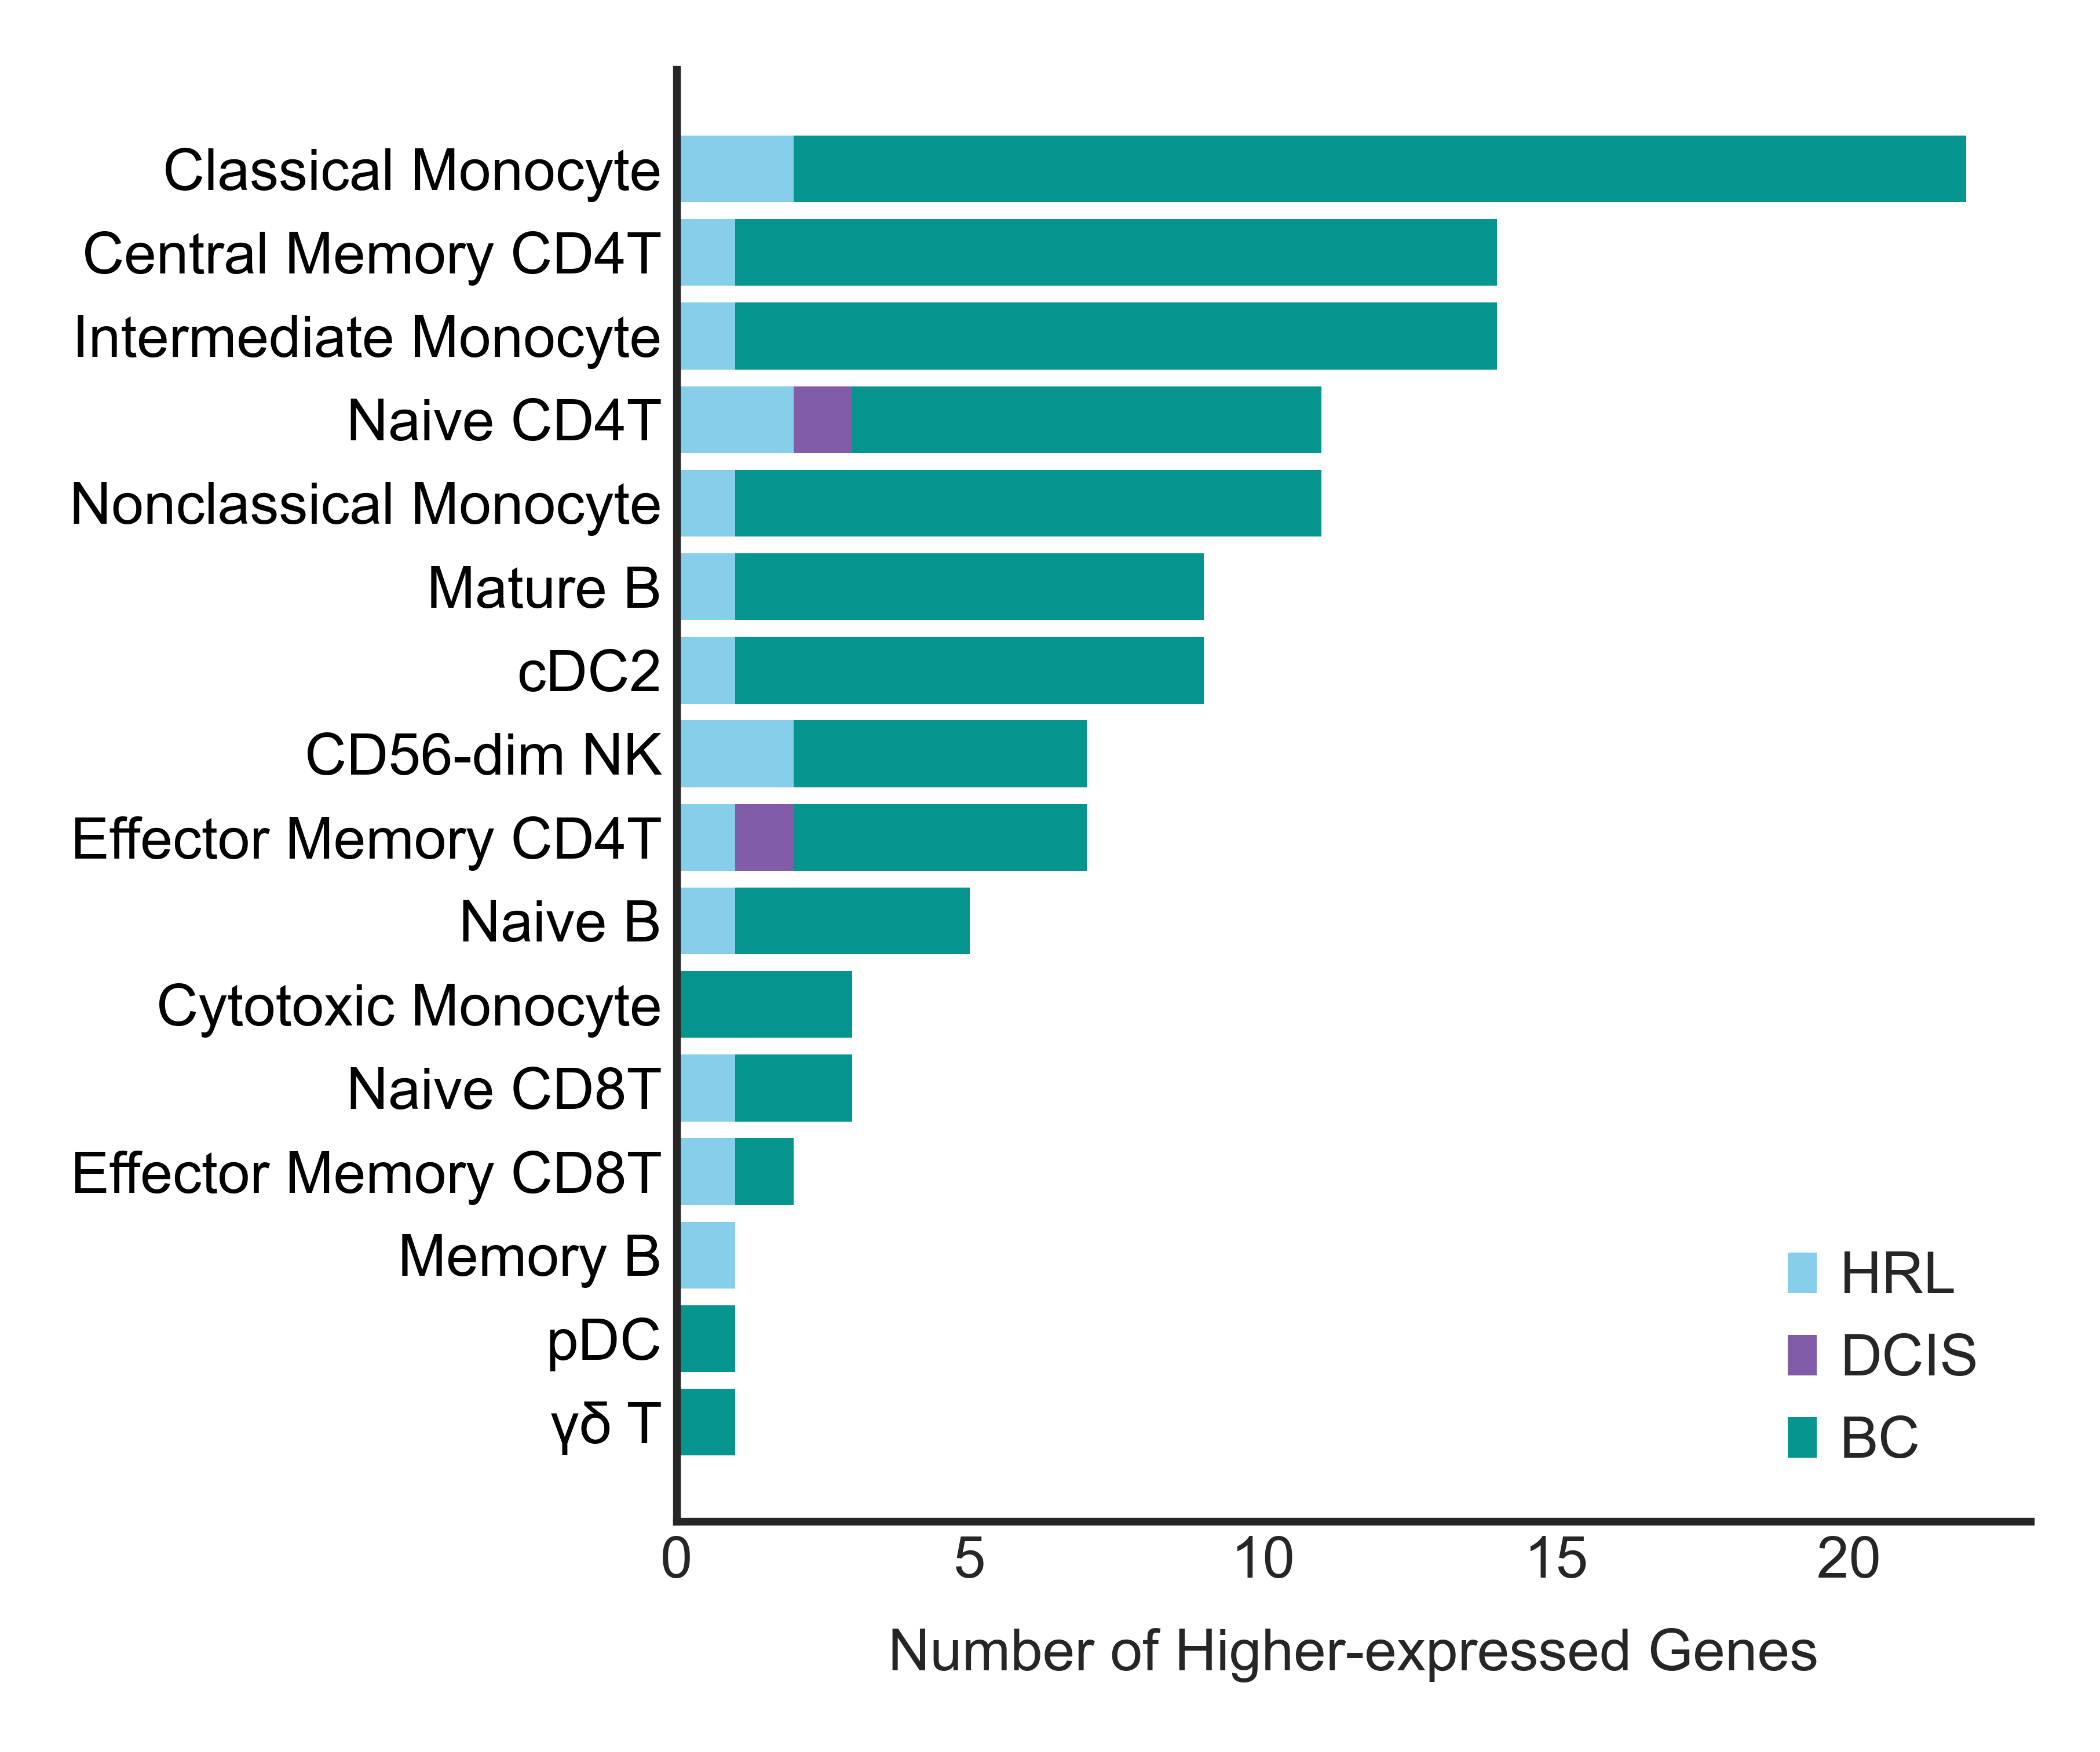

In [56]:
group_palette = {
    'HRL':'skyblue',
    'DCIS':'#825CA6',
    'BC':'#06948E'
}

# 1) Wide table
plot_df = (
    df_counts
    .pivot_table(index='celltype', columns='group', values='count',
                 aggfunc='sum', fill_value=0)
)

group_order = [g for g in ['HRL', 'DCIS', 'BC'] if g in plot_df.columns]
plot_df = plot_df[group_order]

# sort by total count
plot_df = plot_df.loc[plot_df.sum(axis=1).sort_values(ascending=False).index]

# 2) Horizontal stacked bars
plt.figure(figsize=(3, 2.5))
ax = plt.gca()

y = np.arange(plot_df.shape[0])
left = np.zeros(plot_df.shape[0])

for g in group_order:
    vals = plot_df[g].to_numpy()
    ax.barh(
        y, vals,
        left=left,
        color=group_palette.get(g, 'gray'),
        edgecolor='none',
        label=g
    )
    left += vals

# 3) Y tick labels (cell types, all black)
ax.set_yticks(y)
ax.set_yticklabels(plot_df.index.tolist(), fontsize=6, color='black')
ax.tick_params(axis='y', pad=-2)
ax.tick_params(axis='x', pad=-2, labelsize=6)

# optional: highest on top
ax.invert_yaxis()

# 4) Labels and cleanup
ax.set_xlabel('Number of Higher-expressed Genes', fontsize=6)
ax.set_ylabel('')
ax.axvline(0, color='black', linewidth=0.8)
ax.legend(frameon=False, fontsize=6, title='')
sns.despine()

plt.tight_layout()
plt.savefig('plots/F8/barplot_NHBBCsignature_byDzState_horizontal.svg')
plt.show()

In [21]:
# down genes
deg_sel = deg[
    (deg['gene'].isin(gois)) &
    (deg['FDR'] < 0.05) &
    (deg['logFC'] < 0)
    ]

deg_sel

,gene,logFC,logCPM,LR,PValue,FDR,group,celltype


## Enrichment

https://gseapy.readthedocs.io/en/latest/gseapy_example.html

In [29]:
import gseapy as gp

In [30]:
gset = read_gmt('data/08_signature/NHB_up.gmt')
gset.keys()

dict_keys(['NHB-BC Up All', 'NHB-BC Up Protein'])

In [31]:
gois = gset['NHB-BC Up All']['genes']

print(len(gois))

44


In [32]:
for g in gois:
    print(g)

PSPH
IGKV1D-17
GATD3A
LY6E-DT
LINC02363
LRPAP1
MAP1LC3B
LINC00886
HRK
LMNA
SEMA6B
LAPTM4B
KLF8
MTHFD2L
SNHG15
LRG1
AC008957.1
SLC9A3
KLF3
PAIP2
CLCF1
LIPC
C3orf38
TMEM123
PWP2
C2CD4B
ZNF394
RNF11
NIPBL-DT
TIPARP
FAM3A
MBD2
LINC02384
SMAD1
AC240274.1
BFSP2
AC083843.2
JUND
ABHD12
LINC00865
NEBL
HES4
CHMP4B
MAFF


In [33]:
os.listdir('data/11_genesets')

['c2.all.v2024.1.Hs.symbols.gmt',
 'c2.cp.biocarta.v2024.1.Hs.symbols.gmt',
 'c2.cp.kegg_legacy.v2024.1.Hs.symbols.gmt',
 'c2.cp.kegg_medicus.v2024.1.Hs.symbols.gmt',
 'c2.cp.pid.v2024.1.Hs.symbols.gmt',
 'c2.cp.reactome.v2024.1.Hs.symbols.gmt',
 'c2.cp.wikipathways.v2024.1.Hs.symbols.gmt',
 'c3.all.v2024.1.Hs.symbols.gmt',
 'c4.3ca.v2024.1.Hs.symbols.gmt',
 'c4.all.v2024.1.Hs.symbols.gmt',
 'c4.cgn.v2024.1.Hs.symbols.gmt',
 'c4.cm.v2024.1.Hs.symbols.gmt',
 'c5.all.v2024.1.Hs.symbols.gmt',
 'c5.go.bp.v2024.1.Hs.symbols.gmt',
 'c5.go.cc.v2024.1.Hs.symbols.gmt',
 'c5.go.mf.v2024.1.Hs.symbols.gmt',
 'c5.go.v2024.1.Hs.symbols.gmt',
 'c6.all.v2024.1.Hs.symbols.gmt',
 'c7.all.v2024.1.Hs.symbols.gmt',
 'c7.immunesigdb.v2024.1.Hs.symbols.gmt',
 'c7.vax.v2024.1.Hs.symbols.gmt',
 'c8.all.v2024.1.Hs.symbols.gmt',
 'h.all.v2024.1.Hs.symbols.gmt',
 'immport_allgenelist.gmt',
 'oxidative.phosphorylation.gmt']

In [34]:
enr = gp.enrichr(gene_list=gois, # or "./tests/data/gene_list.txt",
                 gene_sets=[
                     'MSigDB_Hallmark_2020',
                     'GO_Biological_Process_2025',
                     'GO_Cellular_Component_2025',
                     'GO_Molecular_Function_2025',
                     'KEGG_2021_Human',
                     'WikiPathways_2024_Human',
                     'data/11_genesets/immport_allgenelist.gmt',

                     'data/11_genesets/h.all.v2024.1.Hs.symbols.gmt',
                     'data/11_genesets/c2.all.v2024.1.Hs.symbols.gmt',
                     'data/11_genesets/c3.all.v2024.1.Hs.symbols.gmt',
                     'data/11_genesets/c4.all.v2024.1.Hs.symbols.gmt',
                     'data/11_genesets/c5.all.v2024.1.Hs.symbols.gmt',
                     'data/11_genesets/c6.all.v2024.1.Hs.symbols.gmt',
                     'data/11_genesets/c7.immunesigdb.v2024.1.Hs.symbols.gmt'
                           ],
                 organism='human', # don't forget to set organism to the one you desired! e.g. Yeast
                 outdir=None, # don't write to disk
                )

res = enr.results.sort_values('P-value')

In [35]:
res.to_csv('data/Figure8/NHBUpAll_enr.csv')

In [36]:
res = pd.read_csv('data/Figure8/NHBUpAll_enr.csv', index_col=0)
res

,Gene_set,Term,Overlap,P-value,Adjusted P-value,Old P-value,Old Adjusted P-value,Odds Ratio,Combined Score,Genes
4720,c7.immunesigdb.v2024.1.Hs.symbols.gmt,GSE10463_CD40L_AND_VA347_VS_CD40L_IN_DC_UP,5/195,0.000025,0.026648,NaN,NaN,17.971775,190.130909,ABHD12;LRG1;MAFF;TIPARP;MAP1LC3B
5434,c7.immunesigdb.v2024.1.Hs.symbols.gmt,GSE22935_UNSTIM_VS_24H_MBOVIS_BCG_STIM_MYD88_K...,5/200,0.000029,0.026648,NaN,NaN,17.507810,183.097630,C3orf38;RNF11;MAP1LC3B;JUND;PAIP2
642,c2.all.v2024.1.Hs.symbols.gmt,BUYTAERT_PHOTODYNAMIC_THERAPY_STRESS_UP,8/822,0.000051,0.013888,NaN,NaN,7.549719,74.636740,PSPH;MAFF;ZNF394;TIPARP;MAP1LC3B;JUND;CLCF1;KLF3
695,c2.all.v2024.1.Hs.symbols.gmt,DAVICIONI_TARGETS_OF_PAX_FOXO1_FUSIONS_UP,5/258,0.000066,0.013888,NaN,NaN,14.621605,140.811910,NEBL;SMAD1;MAFF;MAP1LC3B;LRPAP1
917,c2.all.v2024.1.Hs.symbols.gmt,KOINUMA_COLON_CANCER_MSI_DN,2/8,0.000075,0.013888,NaN,NaN,239.972914,2278.446541,LAPTM4B;CHMP4B
...,...,...,...,...,...,...,...,...,...,...
2752,c5.all.v2024.1.Hs.symbols.gmt,GOBP_CELL_PROJECTION_ORGANIZATION,1/1644,0.945255,0.946681,NaN,NaN,0.501261,0.028221,SEMA6B
3481,c5.all.v2024.1.Hs.symbols.gmt,GOCC_GOLGI_APPARATUS,1/1653,0.946158,0.947109,NaN,NaN,0.498280,0.027578,LRPAP1
354,GO_Cellular_Component_2025,Intracellular Membraneless Organelle (GO:0043232),1/1310,0.949410,0.949410,0.0,0.0,0.331284,0.017198,BFSP2
2870,c5.all.v2024.1.Hs.symbols.gmt,GOBP_INTRACELLULAR_SIGNALING_CASSETTE,1/1952,0.969161,0.969648,NaN,NaN,0.414864,0.012996,SMAD1


In [37]:
res_sel0 = res[res['P-value']<0.05]

Counter(res_sel0['Gene_set'])

Counter({'c5.all.v2024.1.Hs.symbols.gmt': 431,
         'c2.all.v2024.1.Hs.symbols.gmt': 224,
         'c7.immunesigdb.v2024.1.Hs.symbols.gmt': 176,
         'c3.all.v2024.1.Hs.symbols.gmt': 162,
         'GO_Biological_Process_2025': 89,
         'GO_Molecular_Function_2025': 31,
         'WikiPathways_2024_Human': 23,
         'GO_Cellular_Component_2025': 13,
         'c4.all.v2024.1.Hs.symbols.gmt': 7,
         'c6.all.v2024.1.Hs.symbols.gmt': 5,
         'KEGG_2021_Human': 4,
         'h.all.v2024.1.Hs.symbols.gmt': 1,
         'MSigDB_Hallmark_2020': 1,
         'immport_allgenelist.gmt': 1})

In [38]:
res_sel = res[res['Adjusted P-value']<0.1]

res_sel

,Gene_set,Term,Overlap,P-value,Adjusted P-value,Old P-value,Old Adjusted P-value,Odds Ratio,Combined Score,Genes
4720,c7.immunesigdb.v2024.1.Hs.symbols.gmt,GSE10463_CD40L_AND_VA347_VS_CD40L_IN_DC_UP,5/195,0.000025,0.026648,NaN,NaN,17.971775,190.130909,ABHD12;LRG1;MAFF;TIPARP;MAP1LC3B
5434,c7.immunesigdb.v2024.1.Hs.symbols.gmt,GSE22935_UNSTIM_VS_24H_MBOVIS_BCG_STIM_MYD88_K...,5/200,0.000029,0.026648,NaN,NaN,17.507810,183.097630,C3orf38;RNF11;MAP1LC3B;JUND;PAIP2
642,c2.all.v2024.1.Hs.symbols.gmt,BUYTAERT_PHOTODYNAMIC_THERAPY_STRESS_UP,8/822,0.000051,0.013888,NaN,NaN,7.549719,74.636740,PSPH;MAFF;ZNF394;TIPARP;MAP1LC3B;JUND;CLCF1;KLF3
695,c2.all.v2024.1.Hs.symbols.gmt,DAVICIONI_TARGETS_OF_PAX_FOXO1_FUSIONS_UP,5/258,0.000066,0.013888,NaN,NaN,14.621605,140.811910,NEBL;SMAD1;MAFF;MAP1LC3B;LRPAP1
917,c2.all.v2024.1.Hs.symbols.gmt,KOINUMA_COLON_CANCER_MSI_DN,2/8,0.000075,0.013888,NaN,NaN,239.972914,2278.446541,LAPTM4B;CHMP4B
...,...,...,...,...,...,...,...,...,...,...
382,GO_Molecular_Function_2025,Transforming Growth Factor Beta Binding (GO:00...,1/22,0.047322,0.096968,0.0,0.0,22.076412,67.350166,LRG1
385,GO_Molecular_Function_2025,Lipoprotein Particle Binding (GO:0071813),1/23,0.049420,0.096968,0.0,0.0,21.071882,63.371396,LIPC
386,GO_Molecular_Function_2025,Receptor Ligand Activity (GO:0048018),3/380,0.050843,0.096968,0.0,0.0,3.800026,11.320325,SEMA6B;LRPAP1;CLCF1
387,GO_Molecular_Function_2025,Chemorepellent Activity (GO:0045499),1/24,0.051514,0.096968,0.0,0.0,20.154702,59.776822,SEMA6B


In [39]:
res_sel.to_csv('data/Figure8/NHBUpAll_enr_FDR0.1.csv')

In [40]:
res_sel2 = res_sel[res_sel['Gene_set']=='GO_Molecular_Function_2025']
res_sel2

,Gene_set,Term,Overlap,P-value,Adjusted P-value,Old P-value,Old Adjusted P-value,Odds Ratio,Combined Score,Genes
355,GO_Molecular_Function_2025,Cis-Regulatory Region Sequence-Specific DNA Bi...,8/1035,0.001682,0.059751,0.0,0.0,4.095856,26.162705,KLF8;SMAD1;JUND;ZNF394;TIPARP;MAFF;KLF3;HES4
356,GO_Molecular_Function_2025,Carboxylic Ester Hydrolase Activity (GO:0052689),3/111,0.001867,0.059751,0.0,0.0,13.447154,84.492547,ABHD12;LIPC;CLCF1
357,GO_Molecular_Function_2025,Lipase Activity (GO:0016298),2/45,0.004410,0.094077,0.0,0.0,22.052049,119.608499,ABHD12;LIPC
358,GO_Molecular_Function_2025,RNA Polymerase II Cis-Regulatory Region Sequen...,7/1054,0.007678,0.096968,0.0,0.0,3.416789,16.637654,KLF8;SMAD1;JUND;ZNF394;MAFF;KLF3;HES4
359,GO_Molecular_Function_2025,DEAD/H-box RNA Helicase Binding (GO:0017151),1/6,0.013129,0.096968,0.0,0.0,92.795349,402.075033,SMAD1
360,GO_Molecular_Function_2025,Phospholipase Activity (GO:0004620),2/83,0.014379,0.096968,0.0,0.0,11.684303,49.564675,LIPC;CLCF1
361,GO_Molecular_Function_2025,RNA Polymerase II Transcription Regulatory Reg...,7/1236,0.017416,0.096968,0.0,0.0,2.882788,11.676306,KLF8;SMAD1;JUND;ZNF394;MAFF;KLF3;HES4
362,GO_Molecular_Function_2025,co-SMAD Binding (GO:0070410),1/9,0.019630,0.096968,0.0,0.0,57.988372,227.933516,SMAD1
363,GO_Molecular_Function_2025,Type I Transforming Growth Factor Beta Recepto...,1/9,0.019630,0.096968,0.0,0.0,57.988372,227.933516,LRG1
364,GO_Molecular_Function_2025,Type II Transforming Growth Factor Beta Recept...,1/9,0.019630,0.096968,0.0,0.0,57.988372,227.933516,LRG1


In [41]:
dfp = res_sel.sort_values(['Gene_set','Combined Score'], ascending=[True, False])#[res_sel['Gene_set']=='GO_Biological_Process_2025']

dfp['overlap_x'] = [int(x.split('/')[0]) for x in dfp['Overlap']]
dfp['overlap_y'] = [int(x.split('/')[1]) for x in dfp['Overlap']]

dfp = dfp[dfp['overlap_y']>10].reset_index(drop=True)
dfp

,Gene_set,Term,Overlap,P-value,Adjusted P-value,Old P-value,Old Adjusted P-value,Odds Ratio,Combined Score,Genes,overlap_x,overlap_y
0,GO_Biological_Process_2025,Lysosomal Membrane Organization (GO:0097212),2/12,0.000308,0.090199,0.0,0.0,94.980952,768.007879,LAPTM4B;CHMP4B,2,12
1,GO_Cellular_Component_2025,Multivesicular Body Membrane (GO:0032585),2/19,0.000790,0.039492,0.0,0.0,55.851541,398.986059,LAPTM4B;CHMP4B,2,19
2,GO_Cellular_Component_2025,Amphisome (GO:0044753),1/11,0.023941,0.099755,0.0,0.0,46.386047,173.119691,CHMP4B,1,11
3,GO_Cellular_Component_2025,Autophagosome Membrane (GO:0000421),2/36,0.002842,0.071042,0.0,0.0,27.901961,163.599292,MAP1LC3B;CHMP4B,2,36
4,GO_Cellular_Component_2025,Multivesicular Body (GO:0005771),2/49,0.005209,0.076268,0.0,0.0,20.171226,106.046538,LAPTM4B;CHMP4B,2,49
...,...,...,...,...,...,...,...,...,...,...,...,...
62,c7.immunesigdb.v2024.1.Hs.symbols.gmt,GSE18281_CORTICAL_VS_MEDULLARY_THYMOCYTE_DN,4/197,0.000430,0.093791,NaN,NaN,14.041999,108.863259,HRK;MTHFD2L;SEMA6B;MAFF,4,197
63,c7.immunesigdb.v2024.1.Hs.symbols.gmt,GSE36476_CTRL_VS_TSST_ACT_72H_MEMORY_CD4_TCELL...,4/198,0.000438,0.093791,NaN,NaN,13.969113,108.031092,TIPARP;RNF11;TMEM123;KLF3,4,198
64,c7.immunesigdb.v2024.1.Hs.symbols.gmt,GSE42088_UNINF_VS_LEISHMANIA_INF_DC_4H_DN,4/199,0.000446,0.093791,NaN,NaN,13.896973,107.208903,ZNF394;MAP1LC3B;TIPARP;JUND,4,199
65,c7.immunesigdb.v2024.1.Hs.symbols.gmt,GSE14908_RESTING_VS_HDM_STIM_CD4_TCELL_NONATOP...,4/200,0.000455,0.093791,NaN,NaN,13.825567,106.396527,ZNF394;RNF11;TIPARP;TMEM123,4,200


In [42]:
dfp2 = dfp[dfp['Gene_set'].isin(['GO_Molecular_Function_2025'])]
dfp2

,Gene_set,Term,Overlap,P-value,Adjusted P-value,Old P-value,Old Adjusted P-value,Odds Ratio,Combined Score,Genes,overlap_x,overlap_y
10,GO_Molecular_Function_2025,Potassium:Proton Antiporter Activity (GO:0015386),1/11,0.023941,0.096968,0.0,0.0,46.386047,173.119691,SLC9A3,1,11
11,GO_Molecular_Function_2025,Lipoprotein Lipase Activity (GO:0004465),1/12,0.026090,0.096968,0.0,0.0,42.167019,153.749833,LIPC,1,12
12,GO_Molecular_Function_2025,Tropomyosin Binding (GO:0005523),1/13,0.028234,0.096968,0.0,0.0,38.651163,137.877952,NEBL,1,13
13,GO_Molecular_Function_2025,Sodium:Proton Antiporter Activity (GO:0015385),1/13,0.028234,0.096968,0.0,0.0,38.651163,137.877952,SLC9A3,1,13
14,GO_Molecular_Function_2025,Monoacylglycerol Lipase Activity (GO:0047372),1/14,0.030373,0.096968,0.0,0.0,35.676208,124.659899,ABHD12,1,14
15,GO_Molecular_Function_2025,Phosphatidylethanolamine Binding (GO:0008429),1/14,0.030373,0.096968,0.0,0.0,35.676208,124.659899,MAP1LC3B,1,14
16,GO_Molecular_Function_2025,Lipase Activity (GO:0016298),2/45,0.004410,0.094077,0.0,0.0,22.052049,119.608499,ABHD12;LIPC,2,45
17,GO_Molecular_Function_2025,Solute:Potassium Antiporter Activity (GO:0022821),1/15,0.032508,0.096968,0.0,0.0,33.126246,113.499815,SLC9A3,1,15
18,GO_Molecular_Function_2025,I-SMAD Binding (GO:0070411),1/15,0.032508,0.096968,0.0,0.0,33.126246,113.499815,SMAD1,1,15
19,GO_Molecular_Function_2025,Low-Density Lipoprotein Particle Binding (GO:0...,1/16,0.034638,0.096968,0.0,0.0,30.916279,103.965655,LIPC,1,16


In [43]:
for term in dfp2['Term']:
    print(term)

Potassium:Proton Antiporter Activity (GO:0015386)
Lipoprotein Lipase Activity (GO:0004465)
Tropomyosin Binding (GO:0005523)
Sodium:Proton Antiporter Activity (GO:0015385)
Monoacylglycerol Lipase Activity (GO:0047372)
Phosphatidylethanolamine Binding (GO:0008429)
Lipase Activity (GO:0016298)
Solute:Potassium Antiporter Activity (GO:0022821)
I-SMAD Binding (GO:0070411)
Low-Density Lipoprotein Particle Binding (GO:0030169)
Receptor Antagonist Activity (GO:0048019)
Carboxylic Ester Hydrolase Activity (GO:0052689)
Phospholipase A1 Activity (GO:0008970)
Transforming Growth Factor Beta Receptor Binding (GO:0005160)
Lysophospholipase Activity (GO:0004622)
Metal Cation:Proton Antiporter Activity (GO:0051139)
Semaphorin Receptor Binding (GO:0030215)
Triacylglycerol Lipase Activity (GO:0004806)
Transforming Growth Factor Beta Binding (GO:0050431)
Lipoprotein Particle Binding (GO:0071813)
Chemorepellent Activity (GO:0045499)
Low-Density Lipoprotein Particle Receptor Binding (GO:0050750)
Phospholip

/tmp/ipykernel_2794515/2055461399.py:9: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  dfp2['Term'] = [x.split(' (GO')[0] for x in dfp2['Term']]
/tmp/ipykernel_2794515/2055461399.py:27: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_yticklabels(


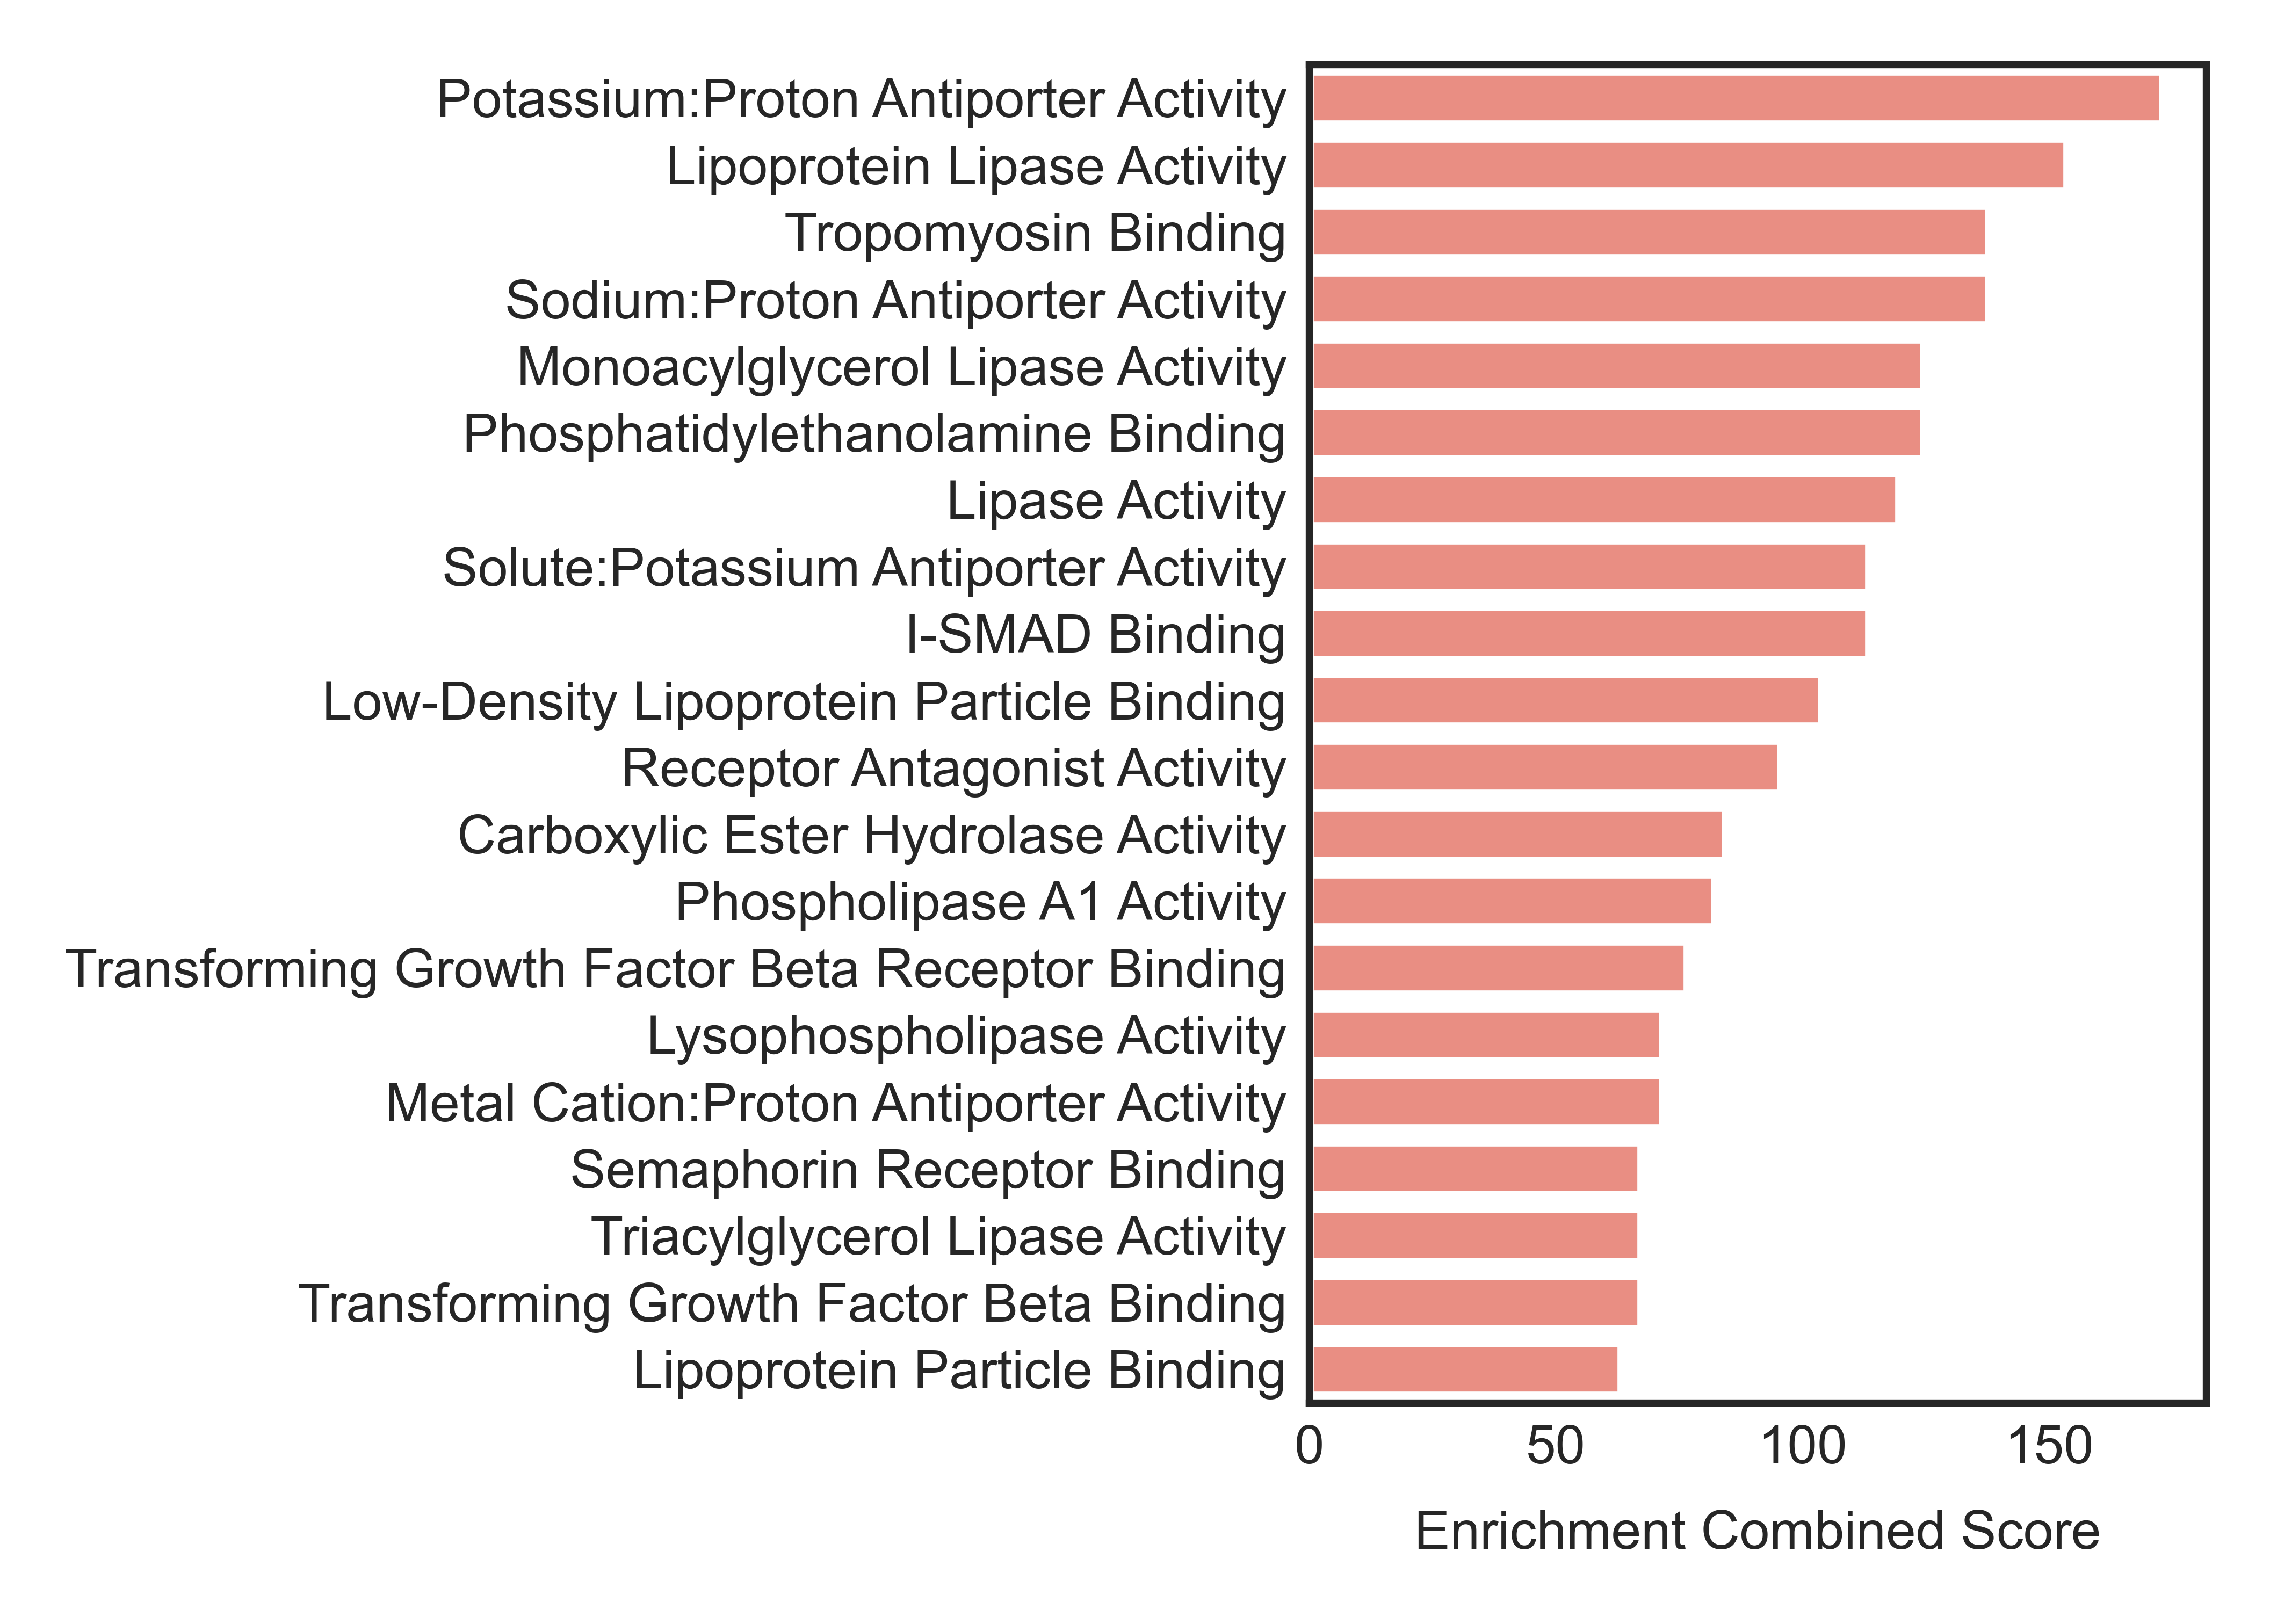

In [57]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import textwrap

# --- figure ---
fig, ax = plt.subplots(figsize=(3.5,2.5))

dfp2['Term'] = [x.split(' (GO')[0] for x in dfp2['Term']]

# Barplot (no error bars)
sns.barplot(
    data=dfp2.iloc[:20,:],
    x="Combined Score",     # numeric values
    y="Term",          # categories
    orient='h',        # vertical bars
    color='salmon',
    errorbar=None,
    ax=ax
)

# Format xtick labels: remove underscores + wrap into 2–3 words per line
def wrap_label(label, width=50):
    """Wrap text to given width for tick labels."""
    return "\n".join(textwrap.wrap(label.replace("_", " "), width=width))

ax.set_yticklabels(
    [wrap_label(t.get_text()) for t in ax.get_yticklabels()],
    rotation=0, fontsize=5#, ha='right', rotation_mode='anchor'
)
ax.tick_params(axis='y', labelsize=6, pad=-1)
ax.tick_params(axis='x', labelsize=6, pad=-1)

# Remove legend if present
if ax.get_legend() is not None:
    ax.legend_.remove()

# Axis labels & title
ax.set_xlabel('Enrichment Combined Score', fontsize=6)
ax.set_ylabel('')
ax.set_title('', fontsize=7, weight='bold')

plt.tight_layout()
plt.savefig('plots/F8/NHBUp_enr.svg', bbox_inches='tight')
plt.show()

## Scores

run `15.1.1_Calc Sig scores R.ipynb`

In [8]:
scores = pd.read_csv(
    'data/08_signature/ssgsea_NHBSig_IWSCdataset.csv',
    index_col=0
)

scores

,orig.ident,dataset_name,celltype_level3,NHB-BC Up All,NHB-BC Up Protein
Pool137-10_CD56-bright NK,Pool137-10_CD56-bright NK,Pool137-10,CD56-bright NK,0.692580,0.863773
Pool137-10_CD56-dim NK,Pool137-10_CD56-dim NK,Pool137-10,CD56-dim NK,0.788053,0.939270
Pool137-10_cDC1,Pool137-10_cDC1,Pool137-10,cDC1,0.689782,0.838855
Pool137-10_cDC2,Pool137-10_cDC2,Pool137-10,cDC2,0.839779,0.987749
Pool137-10_Central Memory CD4T,Pool137-10_Central Memory CD4T,Pool137-10,Central Memory CD4T,0.706103,0.866657
...,...,...,...,...,...
Pool138-9_Nonclassical Monocyte,Pool138-9_Nonclassical Monocyte,Pool138-9,Nonclassical Monocyte,0.898382,1.041844
Pool138-9_pDC,Pool138-9_pDC,Pool138-9,pDC,0.664185,0.783944
Pool138-9_Plasmablast,Pool138-9_Plasmablast,Pool138-9,Plasmablast,0.785479,0.874262
Pool138-9_Proliferating NK,Pool138-9_Proliferating NK,Pool138-9,Proliferating NK,0.515037,0.696860


In [9]:
scores['dataset_name'] = [
    x.replace('-','_') for x in scores['dataset_name']
]

In [10]:
meta = pd.read_csv(
    'data/01_meta/meta_pt.csv',
    index_col=0
)

print(meta.shape)
meta

(55, 9)


,dataset_name,batch,viability_pct,group,race,age,diabetes,obesity,race-stage
sampleid,,,,,,,,,
9-D,Pool137_7,1,95,DCIS,NHW,37.0,N,N,NHW-DCIS
30-D,Pool137_12,1,92,DCIS,NHW,78.0,N,N,NHW-DCIS
36-D,Pool137_18,1,93,DCIS,NHB,39.0,N,N,NHB-DCIS
119-D,Pool137_20,1,95,DCIS,NHB,80.0,N,N,NHB-DCIS
28-D,Pool137_24,1,94,DCIS,NHW,53.0,N,N,NHW-DCIS
53-D,Pool137_27,1,96,DCIS,NHB,45.0,N,N,NHB-DCIS
77-D,Pool137_30,1,90,DCIS,NHW,45.0,N,N,NHW-DCIS
31-D,Pool138_6,2,93,DCIS,NHW,44.0,N,N,NHW-DCIS
6-H,Pool137_6,1,94,HRL,NHW,71.1,N,Y,NHW-HRL


In [11]:
mg = pd.merge(
    scores, meta, on='dataset_name'
)

mg['race']

0       NHW
1       NHW
2       NHW
3       NHW
4       NHW
       ... 
1336    NHW
1337    NHW
1338    NHW
1339    NHW
1340    NHW
Name: race, Length: 1341, dtype: object

In [12]:
mg['race_group'] = mg['race'] + '-' + mg['group']
mg['race_group'] = pd.Categorical(
    mg['race_group'], 
    categories=['NHW-HRL','NHB-HRL',
'NHW-DCIS', 'NHB-DCIS', 
'NHW-BC','NHB-BC'
                # 'NHB | HRL',
                # 'NHB | DCIS', 
                # 'NHB | BC'
               ]
)
mg['race_group'].unique()

['NHW-HRL', 'NHW-BC', 'NHW-DCIS', 'NHB-BC', 'NHB-DCIS', 'NHB-HRL']
Categories (6, object): ['NHW-HRL', 'NHB-HRL', 'NHW-DCIS', 'NHB-DCIS', 'NHW-BC', 'NHB-BC']

In [13]:
celltypes = mg['celltype_level3'].unique().tolist()
celltypes

['CD56-bright NK',
 'CD56-dim NK',
 'cDC1',
 'cDC2',
 'Central Memory CD4T',
 'Central Memory CD8T',
 'Classical Monocyte',
 'Cytotoxic CD4T',
 'Cytotoxic Monocyte',
 'Double Negative T',
 'Effector Memory CD4T',
 'Effector Memory CD8T',
 'Intermediate Monocyte',
 'MAIT',
 'Mature B',
 'Memory B',
 'Naive B',
 'Naive CD4T',
 'Naive CD8T',
 'Nonclassical Monocyte',
 'pDC',
 'Plasmablast',
 'Proliferating NK',
 'Treg',
 'γδ T']

/tmp/ipykernel_3430753/1158281851.py:62: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:gray'` for the same effect.

  sns.stripplot(data=df, x='group', y='expr', hue='group', color='gray', alpha=0.4, linewidth=0, size=1, ax=ax)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

NHW-HRL vs. NHB-HRL: Mann-Whitney-Wilcoxon test two-sided with Benjamini-Hochberg correction, P_val:5.795e-03 U_stat=1.300e+01
NHW-DCIS vs. NHB-DCIS: Mann-Whitney-Wilcoxon test two-sided with Benjamini-Hochberg correction, P_val:2.571e-01 U_stat=6.000e+00
NHW-BC vs. NHB-BC: Mann-Whitney-Wilcoxon test two-sided with Benjamini-Hochberg correction, P_val:2.136e-03 U_stat=1.800e+01


/tmp/ipykernel_3430753/1158281851.py:62: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:gray'` for the same effect.

  sns.stripplot(data=df, x='group', y='expr', hue='group', color='gray', alpha=0.4, linewidth=0, size=1, ax=ax)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

NHW-HRL vs. NHB-HRL: Mann-Whitney-Wilcoxon test two-sided with Benjamini-Hochberg correction, P_val:9.108e-03 U_stat=1.500e+01
NHW-DCIS vs. NHB-DCIS: Mann-Whitney-Wilcoxon test two-sided with Benjamini-Hochberg correction, P_val:3.810e-02 U_stat=2.000e+00
NHW-BC vs. NHB-BC: Mann-Whitney-Wilcoxon test two-sided with Benjamini-Hochberg correction, P_val:2.493e-05 U_stat=0.000e+00


/tmp/ipykernel_3430753/1158281851.py:62: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:gray'` for the same effect.

  sns.stripplot(data=df, x='group', y='expr', hue='group', color='gray', alpha=0.4, linewidth=0, size=1, ax=ax)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

NHW-HRL vs. NHB-HRL: Mann-Whitney-Wilcoxon test two-sided with Benjamini-Hochberg correction, P_val:5.956e-01 U_stat=3.800e+01
NHW-DCIS vs. NHB-DCIS: Mann-Whitney-Wilcoxon test two-sided with Benjamini-Hochberg correction, P_val:9.143e-01 U_stat=1.300e+01
NHW-BC vs. NHB-BC: Mann-Whitney-Wilcoxon test two-sided with Benjamini-Hochberg correction, P_val:7.093e-03 U_stat=2.800e+01


/tmp/ipykernel_3430753/1158281851.py:62: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:gray'` for the same effect.

  sns.stripplot(data=df, x='group', y='expr', hue='group', color='gray', alpha=0.4, linewidth=0, size=1, ax=ax)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

NHW-HRL vs. NHB-HRL: Mann-Whitney-Wilcoxon test two-sided with Benjamini-Hochberg correction, P_val:2.413e-01 U_stat=3.400e+01
NHW-DCIS vs. NHB-DCIS: Mann-Whitney-Wilcoxon test two-sided with Benjamini-Hochberg correction, P_val:2.619e-01 U_stat=4.000e+00
NHW-BC vs. NHB-BC: Mann-Whitney-Wilcoxon test two-sided with Benjamini-Hochberg correction, P_val:9.991e-04 U_stat=1.700e+01


/tmp/ipykernel_3430753/1158281851.py:62: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:gray'` for the same effect.

  sns.stripplot(data=df, x='group', y='expr', hue='group', color='gray', alpha=0.4, linewidth=0, size=1, ax=ax)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

NHW-HRL vs. NHB-HRL: Mann-Whitney-Wilcoxon test two-sided with Benjamini-Hochberg correction, P_val:2.202e-03 U_stat=9.000e+00
NHW-DCIS vs. NHB-DCIS: Mann-Whitney-Wilcoxon test two-sided with Benjamini-Hochberg correction, P_val:3.810e-02 U_stat=2.000e+00
NHW-BC vs. NHB-BC: Mann-Whitney-Wilcoxon test two-sided with Benjamini-Hochberg correction, P_val:2.493e-05 U_stat=0.000e+00


/tmp/ipykernel_3430753/1158281851.py:62: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:gray'` for the same effect.

  sns.stripplot(data=df, x='group', y='expr', hue='group', color='gray', alpha=0.4, linewidth=0, size=1, ax=ax)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

NHW-HRL vs. NHB-HRL: Mann-Whitney-Wilcoxon test two-sided with Benjamini-Hochberg correction, P_val:5.390e-02 U_stat=2.400e+01
NHW-DCIS vs. NHB-DCIS: Mann-Whitney-Wilcoxon test two-sided with Benjamini-Hochberg correction, P_val:6.667e-02 U_stat=3.000e+00
NHW-BC vs. NHB-BC: Mann-Whitney-Wilcoxon test two-sided with Benjamini-Hochberg correction, P_val:5.525e-04 U_stat=1.400e+01


/tmp/ipykernel_3430753/1158281851.py:62: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:gray'` for the same effect.

  sns.stripplot(data=df, x='group', y='expr', hue='group', color='gray', alpha=0.4, linewidth=0, size=1, ax=ax)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

NHW-HRL vs. NHB-HRL: Mann-Whitney-Wilcoxon test two-sided with Benjamini-Hochberg correction, P_val:4.515e-02 U_stat=2.300e+01
NHW-DCIS vs. NHB-DCIS: Mann-Whitney-Wilcoxon test two-sided with Benjamini-Hochberg correction, P_val:9.524e-03 U_stat=0.000e+00
NHW-BC vs. NHB-BC: Mann-Whitney-Wilcoxon test two-sided with Benjamini-Hochberg correction, P_val:2.493e-05 U_stat=0.000e+00


/tmp/ipykernel_3430753/1158281851.py:62: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:gray'` for the same effect.

  sns.stripplot(data=df, x='group', y='expr', hue='group', color='gray', alpha=0.4, linewidth=0, size=1, ax=ax)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

NHW-HRL vs. NHB-HRL: Mann-Whitney-Wilcoxon test two-sided with Benjamini-Hochberg correction, P_val:7.566e-02 U_stat=2.600e+01
NHW-DCIS vs. NHB-DCIS: Mann-Whitney-Wilcoxon test two-sided with Benjamini-Hochberg correction, P_val:3.810e-02 (ns) U_stat=2.000e+00
NHW-BC vs. NHB-BC: Mann-Whitney-Wilcoxon test two-sided with Benjamini-Hochberg correction, P_val:4.711e-02 (ns) U_stat=4.100e+01


/tmp/ipykernel_3430753/1158281851.py:62: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:gray'` for the same effect.

  sns.stripplot(data=df, x='group', y='expr', hue='group', color='gray', alpha=0.4, linewidth=0, size=1, ax=ax)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

NHW-HRL vs. NHB-HRL: Mann-Whitney-Wilcoxon test two-sided with Benjamini-Hochberg correction, P_val:9.097e-01 U_stat=4.800e+01
NHW-DCIS vs. NHB-DCIS: Mann-Whitney-Wilcoxon test two-sided with Benjamini-Hochberg correction, P_val:4.762e-01 U_stat=8.000e+00
NHW-BC vs. NHB-BC: Mann-Whitney-Wilcoxon test two-sided with Benjamini-Hochberg correction, P_val:5.072e-05 U_stat=3.000e+00


/tmp/ipykernel_3430753/1158281851.py:62: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:gray'` for the same effect.

  sns.stripplot(data=df, x='group', y='expr', hue='group', color='gray', alpha=0.4, linewidth=0, size=1, ax=ax)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

NHW-HRL vs. NHB-HRL: Mann-Whitney-Wilcoxon test two-sided with Benjamini-Hochberg correction, P_val:1.530e-01 U_stat=2.700e+01
NHW-DCIS vs. NHB-DCIS: Mann-Whitney-Wilcoxon test two-sided with Benjamini-Hochberg correction, P_val:5.333e-01 U_stat=2.000e+00
NHW-BC vs. NHB-BC: Mann-Whitney-Wilcoxon test two-sided with Benjamini-Hochberg correction, P_val:3.173e-02 (ns) U_stat=2.400e+01


/tmp/ipykernel_3430753/1158281851.py:62: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:gray'` for the same effect.

  sns.stripplot(data=df, x='group', y='expr', hue='group', color='gray', alpha=0.4, linewidth=0, size=1, ax=ax)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

NHW-HRL vs. NHB-HRL: Mann-Whitney-Wilcoxon test two-sided with Benjamini-Hochberg correction, P_val:4.396e-04 U_stat=3.000e+00
NHW-DCIS vs. NHB-DCIS: Mann-Whitney-Wilcoxon test two-sided with Benjamini-Hochberg correction, P_val:9.524e-03 U_stat=0.000e+00
NHW-BC vs. NHB-BC: Mann-Whitney-Wilcoxon test two-sided with Benjamini-Hochberg correction, P_val:2.493e-05 U_stat=0.000e+00


/tmp/ipykernel_3430753/1158281851.py:62: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:gray'` for the same effect.

  sns.stripplot(data=df, x='group', y='expr', hue='group', color='gray', alpha=0.4, linewidth=0, size=1, ax=ax)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

NHW-HRL vs. NHB-HRL: Mann-Whitney-Wilcoxon test two-sided with Benjamini-Hochberg correction, P_val:4.515e-02 U_stat=2.300e+01
NHW-DCIS vs. NHB-DCIS: Mann-Whitney-Wilcoxon test two-sided with Benjamini-Hochberg correction, P_val:3.810e-02 U_stat=2.000e+00
NHW-BC vs. NHB-BC: Mann-Whitney-Wilcoxon test two-sided with Benjamini-Hochberg correction, P_val:5.525e-04 U_stat=1.400e+01


/tmp/ipykernel_3430753/1158281851.py:62: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:gray'` for the same effect.

  sns.stripplot(data=df, x='group', y='expr', hue='group', color='gray', alpha=0.4, linewidth=0, size=1, ax=ax)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

NHW-HRL vs. NHB-HRL: Mann-Whitney-Wilcoxon test two-sided with Benjamini-Hochberg correction, P_val:4.515e-02 U_stat=2.300e+01
NHW-DCIS vs. NHB-DCIS: Mann-Whitney-Wilcoxon test two-sided with Benjamini-Hochberg correction, P_val:3.810e-02 U_stat=2.000e+00
NHW-BC vs. NHB-BC: Mann-Whitney-Wilcoxon test two-sided with Benjamini-Hochberg correction, P_val:3.168e-05 U_stat=1.000e+00


/tmp/ipykernel_3430753/1158281851.py:62: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:gray'` for the same effect.

  sns.stripplot(data=df, x='group', y='expr', hue='group', color='gray', alpha=0.4, linewidth=0, size=1, ax=ax)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

NHW-HRL vs. NHB-HRL: Mann-Whitney-Wilcoxon test two-sided with Benjamini-Hochberg correction, P_val:7.133e-01 U_stat=4.000e+01
NHW-DCIS vs. NHB-DCIS: Mann-Whitney-Wilcoxon test two-sided with Benjamini-Hochberg correction, P_val:1.000e+00 U_stat=1.200e+01
NHW-BC vs. NHB-BC: Mann-Whitney-Wilcoxon test two-sided with Benjamini-Hochberg correction, P_val:2.071e-01 U_stat=4.500e+01


/tmp/ipykernel_3430753/1158281851.py:62: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:gray'` for the same effect.

  sns.stripplot(data=df, x='group', y='expr', hue='group', color='gray', alpha=0.4, linewidth=0, size=1, ax=ax)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

NHW-HRL vs. NHB-HRL: Mann-Whitney-Wilcoxon test two-sided with Benjamini-Hochberg correction, P_val:4.586e-03 U_stat=1.200e+01
NHW-DCIS vs. NHB-DCIS: Mann-Whitney-Wilcoxon test two-sided with Benjamini-Hochberg correction, P_val:1.905e-02 U_stat=1.000e+00
NHW-BC vs. NHB-BC: Mann-Whitney-Wilcoxon test two-sided with Benjamini-Hochberg correction, P_val:2.493e-05 U_stat=0.000e+00


/tmp/ipykernel_3430753/1158281851.py:62: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:gray'` for the same effect.

  sns.stripplot(data=df, x='group', y='expr', hue='group', color='gray', alpha=0.4, linewidth=0, size=1, ax=ax)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

NHW-HRL vs. NHB-HRL: Mann-Whitney-Wilcoxon test two-sided with Benjamini-Hochberg correction, P_val:5.828e-04 U_stat=4.000e+00
NHW-DCIS vs. NHB-DCIS: Mann-Whitney-Wilcoxon test two-sided with Benjamini-Hochberg correction, P_val:6.667e-02 U_stat=3.000e+00
NHW-BC vs. NHB-BC: Mann-Whitney-Wilcoxon test two-sided with Benjamini-Hochberg correction, P_val:5.525e-04 U_stat=1.400e+01


/tmp/ipykernel_3430753/1158281851.py:62: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:gray'` for the same effect.

  sns.stripplot(data=df, x='group', y='expr', hue='group', color='gray', alpha=0.4, linewidth=0, size=1, ax=ax)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

NHW-HRL vs. NHB-HRL: Mann-Whitney-Wilcoxon test two-sided with Benjamini-Hochberg correction, P_val:3.121e-02 U_stat=2.100e+01
NHW-DCIS vs. NHB-DCIS: Mann-Whitney-Wilcoxon test two-sided with Benjamini-Hochberg correction, P_val:9.524e-03 U_stat=0.000e+00
NHW-BC vs. NHB-BC: Mann-Whitney-Wilcoxon test two-sided with Benjamini-Hochberg correction, P_val:2.493e-05 U_stat=0.000e+00


/tmp/ipykernel_3430753/1158281851.py:62: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:gray'` for the same effect.

  sns.stripplot(data=df, x='group', y='expr', hue='group', color='gray', alpha=0.4, linewidth=0, size=1, ax=ax)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

NHW-HRL vs. NHB-HRL: Mann-Whitney-Wilcoxon test two-sided with Benjamini-Hochberg correction, P_val:1.827e-04 U_stat=0.000e+00
NHW-DCIS vs. NHB-DCIS: Mann-Whitney-Wilcoxon test two-sided with Benjamini-Hochberg correction, P_val:9.524e-03 U_stat=0.000e+00
NHW-BC vs. NHB-BC: Mann-Whitney-Wilcoxon test two-sided with Benjamini-Hochberg correction, P_val:2.493e-05 U_stat=0.000e+00


/tmp/ipykernel_3430753/1158281851.py:62: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:gray'` for the same effect.

  sns.stripplot(data=df, x='group', y='expr', hue='group', color='gray', alpha=0.4, linewidth=0, size=1, ax=ax)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

NHW-HRL vs. NHB-HRL: Mann-Whitney-Wilcoxon test two-sided with Benjamini-Hochberg correction, P_val:5.828e-04 U_stat=4.000e+00
NHW-DCIS vs. NHB-DCIS: Mann-Whitney-Wilcoxon test two-sided with Benjamini-Hochberg correction, P_val:2.857e-01 U_stat=5.000e+00
NHW-BC vs. NHB-BC: Mann-Whitney-Wilcoxon test two-sided with Benjamini-Hochberg correction, P_val:3.168e-05 U_stat=1.000e+00


/tmp/ipykernel_3430753/1158281851.py:62: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:gray'` for the same effect.

  sns.stripplot(data=df, x='group', y='expr', hue='group', color='gray', alpha=0.4, linewidth=0, size=1, ax=ax)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

NHW-HRL vs. NHB-HRL: Mann-Whitney-Wilcoxon test two-sided with Benjamini-Hochberg correction, P_val:2.202e-03 U_stat=9.000e+00
NHW-DCIS vs. NHB-DCIS: Mann-Whitney-Wilcoxon test two-sided with Benjamini-Hochberg correction, P_val:1.143e-01 U_stat=4.000e+00
NHW-BC vs. NHB-BC: Mann-Whitney-Wilcoxon test two-sided with Benjamini-Hochberg correction, P_val:2.493e-05 U_stat=0.000e+00


/tmp/ipykernel_3430753/1158281851.py:62: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:gray'` for the same effect.

  sns.stripplot(data=df, x='group', y='expr', hue='group', color='gray', alpha=0.4, linewidth=0, size=1, ax=ax)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

NHW-HRL vs. NHB-HRL: Mann-Whitney-Wilcoxon test two-sided with Benjamini-Hochberg correction, P_val:2.113e-02 U_stat=1.900e+01
NHW-DCIS vs. NHB-DCIS: Mann-Whitney-Wilcoxon test two-sided with Benjamini-Hochberg correction, P_val:6.667e-02 U_stat=3.000e+00
NHW-BC vs. NHB-BC: Mann-Whitney-Wilcoxon test two-sided with Benjamini-Hochberg correction, P_val:2.493e-05 U_stat=0.000e+00


/tmp/ipykernel_3430753/1158281851.py:62: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:gray'` for the same effect.

  sns.stripplot(data=df, x='group', y='expr', hue='group', color='gray', alpha=0.4, linewidth=0, size=1, ax=ax)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

NHW-HRL vs. NHB-HRL: Mann-Whitney-Wilcoxon test two-sided with Benjamini-Hochberg correction, P_val:3.611e-03 U_stat=1.100e+01
NHW-DCIS vs. NHB-DCIS: Mann-Whitney-Wilcoxon test two-sided with Benjamini-Hochberg correction, P_val:3.810e-01 U_stat=5.000e+00
NHW-BC vs. NHB-BC: Mann-Whitney-Wilcoxon test two-sided with Benjamini-Hochberg correction, P_val:2.437e-03 U_stat=1.900e+01


/tmp/ipykernel_3430753/1158281851.py:62: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:gray'` for the same effect.

  sns.stripplot(data=df, x='group', y='expr', hue='group', color='gray', alpha=0.4, linewidth=0, size=1, ax=ax)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

NHW-HRL vs. NHB-HRL: Mann-Whitney-Wilcoxon test two-sided with Benjamini-Hochberg correction, P_val:6.402e-02 U_stat=2.500e+01
NHW-DCIS vs. NHB-DCIS: Mann-Whitney-Wilcoxon test two-sided with Benjamini-Hochberg correction, P_val:5.476e-01 U_stat=6.000e+00
NHW-BC vs. NHB-BC: Mann-Whitney-Wilcoxon test two-sided with Benjamini-Hochberg correction, P_val:1.827e-01 U_stat=5.300e+01


/tmp/ipykernel_3430753/1158281851.py:62: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:gray'` for the same effect.

  sns.stripplot(data=df, x='group', y='expr', hue='group', color='gray', alpha=0.4, linewidth=0, size=1, ax=ax)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

NHW-HRL vs. NHB-HRL: Mann-Whitney-Wilcoxon test two-sided with Benjamini-Hochberg correction, P_val:1.402e-02 U_stat=1.700e+01
NHW-DCIS vs. NHB-DCIS: Mann-Whitney-Wilcoxon test two-sided with Benjamini-Hochberg correction, P_val:1.143e-01 U_stat=4.000e+00
NHW-BC vs. NHB-BC: Mann-Whitney-Wilcoxon test two-sided with Benjamini-Hochberg correction, P_val:1.762e-03 U_stat=2.000e+01


/tmp/ipykernel_3430753/1158281851.py:62: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:gray'` for the same effect.

  sns.stripplot(data=df, x='group', y='expr', hue='group', color='gray', alpha=0.4, linewidth=0, size=1, ax=ax)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

NHW-HRL vs. NHB-HRL: Mann-Whitney-Wilcoxon test two-sided with Benjamini-Hochberg correction, P_val:6.354e-01 U_stat=2.500e+01
NHW-DCIS vs. NHB-DCIS: Mann-Whitney-Wilcoxon test two-sided with Benjamini-Hochberg correction, P_val:7.143e-01 U_stat=1.100e+01
NHW-BC vs. NHB-BC: Mann-Whitney-Wilcoxon test two-sided with Benjamini-Hochberg correction, P_val:1.645e-01 U_stat=1.300e+01


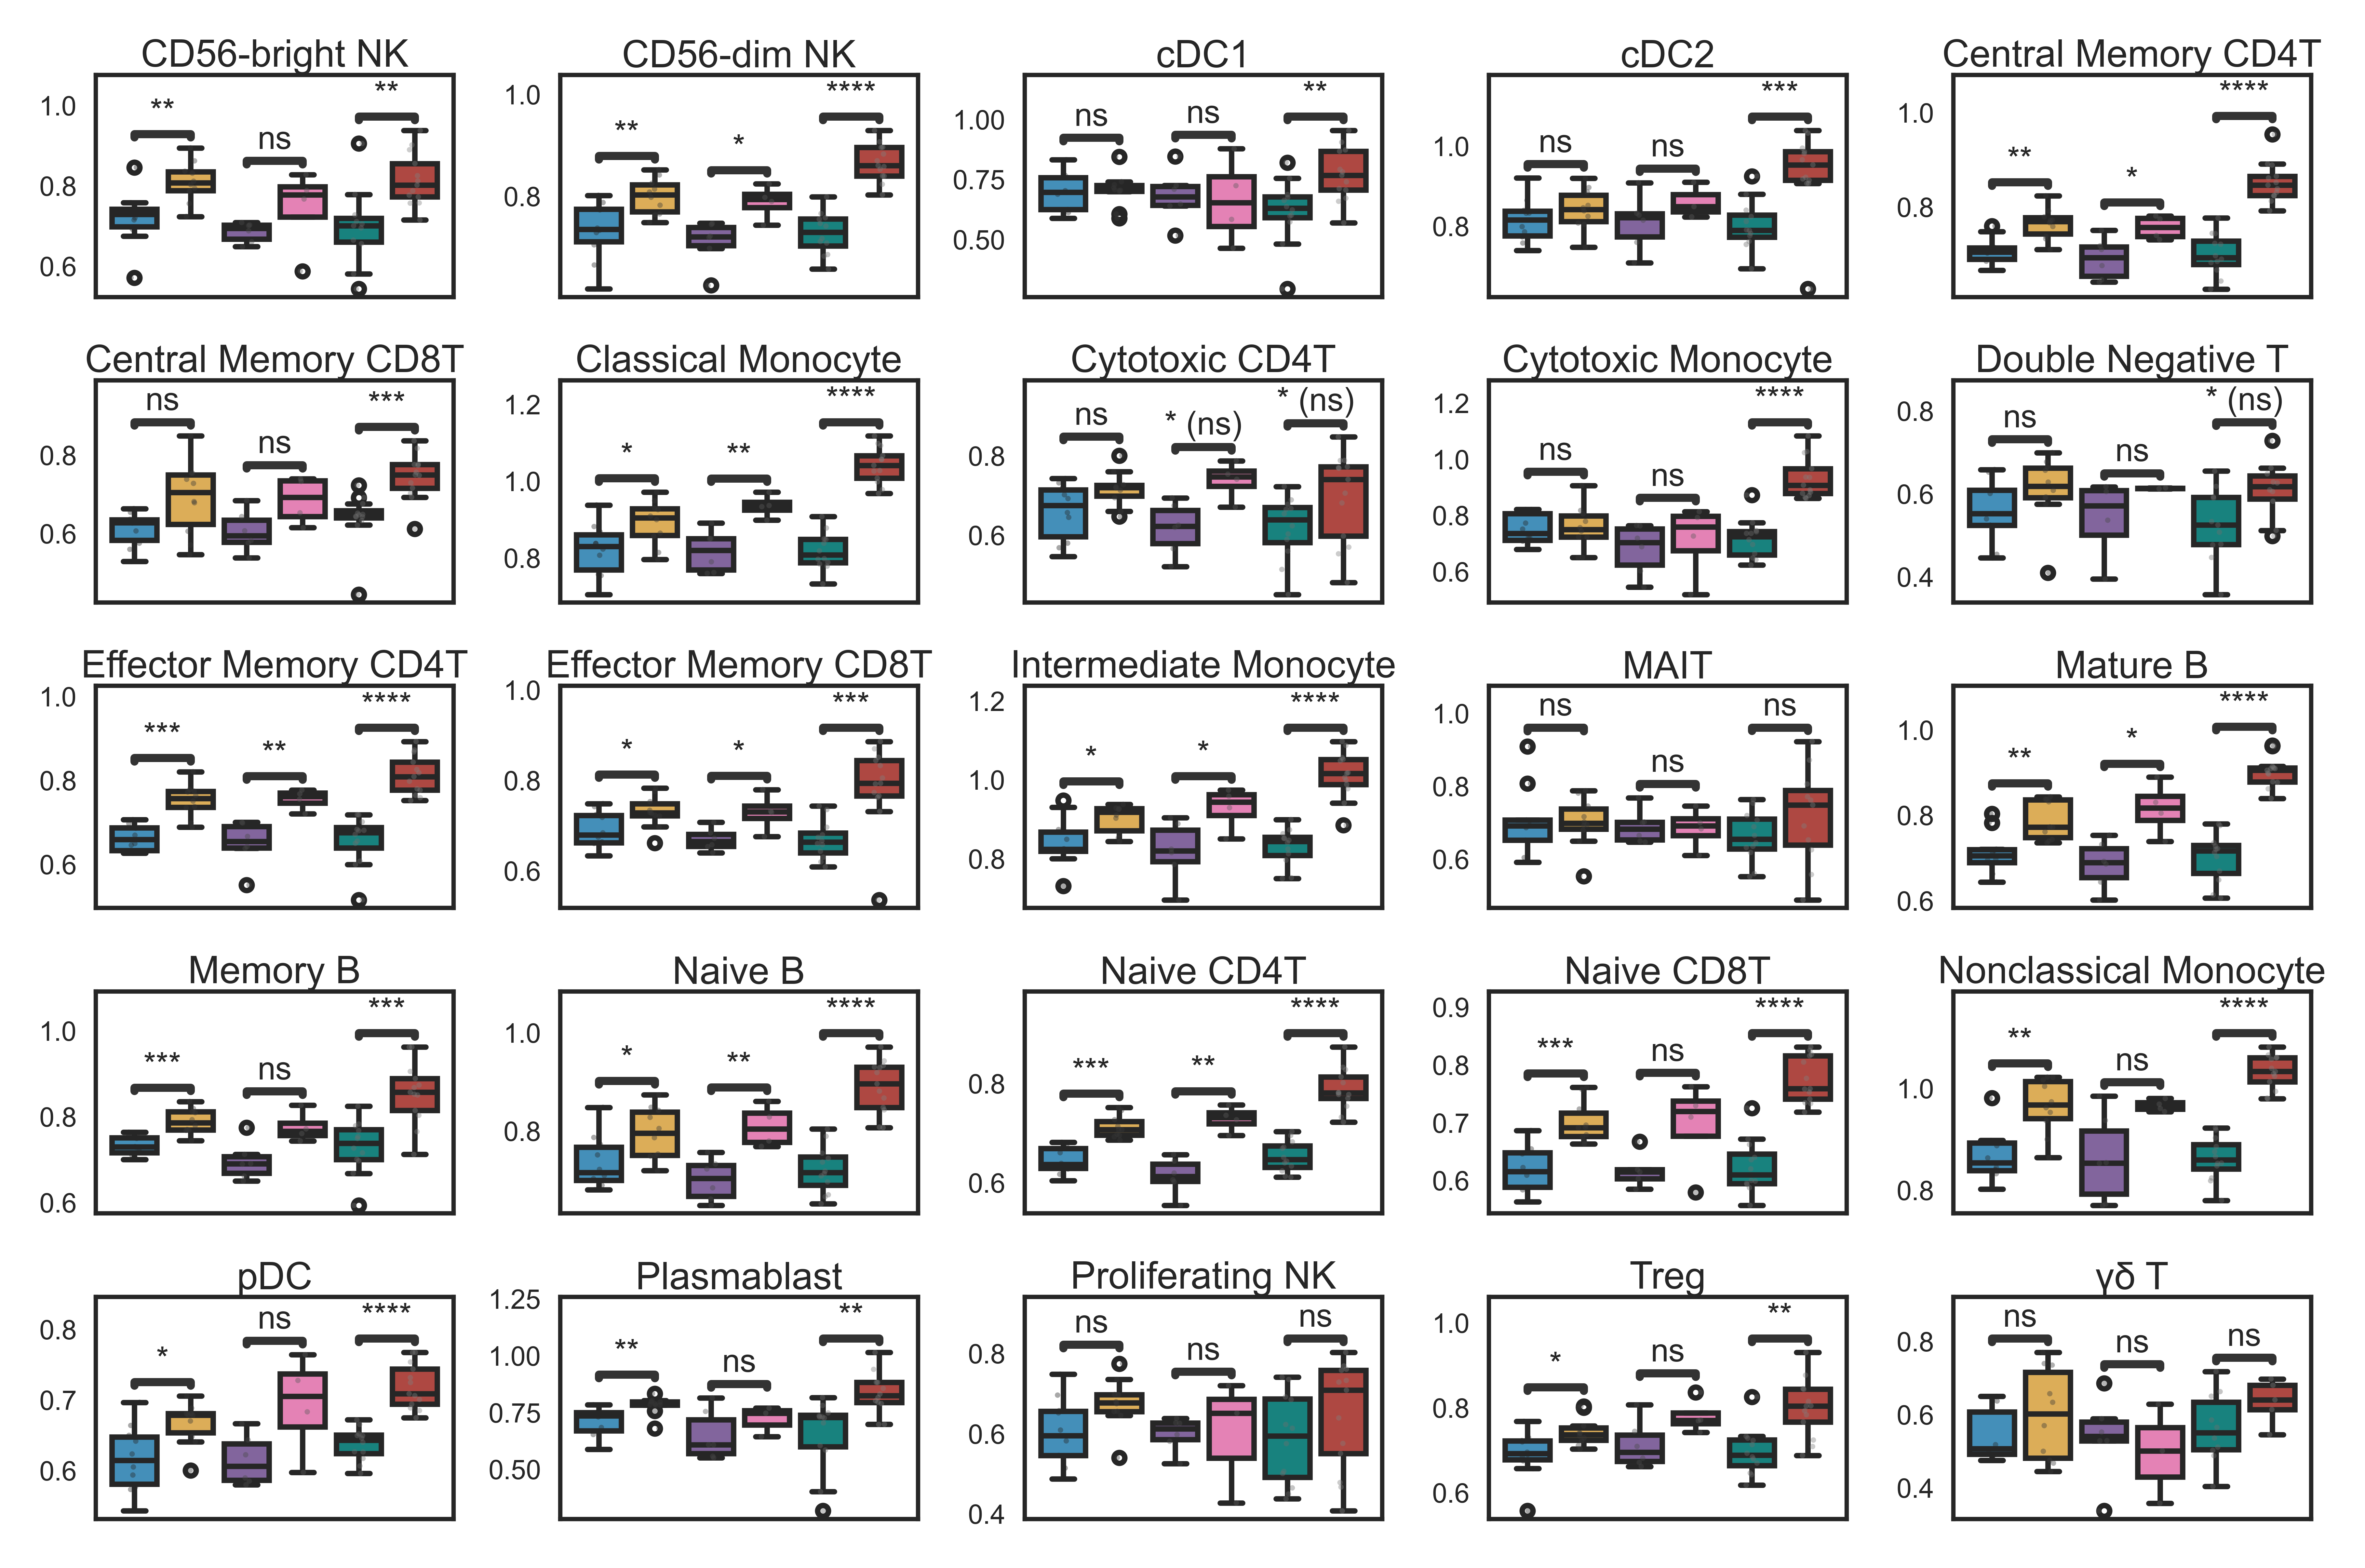

In [14]:
# all genes, regardless of protein coding
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
from statannotations.Annotator import Annotator


rcParams.update({
    'font.family': 'Arial',
    'svg.fonttype': 'none', # Keeps text as font
    
    'font.size': 6,  # 5–7 pt as per guidelines
    'axes.titlesize': 7,
    'axes.labelsize': 6,
    'xtick.labelsize': 5,
    'ytick.labelsize': 5,

    'legend.fontsize': 6,
    'legend.title_fontsize': 6,
    
    'figure.dpi': 600
})




palette = {
    'NHW-HRL':'#3194CC',
    'NHW-DCIS':'#825CA6',
    'NHW-BC':'#06948E',
    
    'NHB-HRL':'#F2B342',
    'NHB-DCIS':'#F472B6',
    'NHB-BC':'#C03830',

    'Diabetes':'navy',
    'Obesity':'salmon'
}


n_cells = len(celltypes)
ncol = 5
nrow = int(np.ceil(n_cells / ncol))

fig, axes = plt.subplots(nrow, ncol, figsize=(6, nrow*.8), sharey=False, sharex=True)
axes = axes.flatten()

fig.subplots_adjust(
    wspace=0.4,   # horizontal space between subplots
    hspace=0.35)
    
for i, cell in enumerate(celltypes):
    ax = axes[i]
    
    tmp = mg[mg['celltype_level3']==cell]
    
    df = pd.DataFrame({
        'expr': tmp['NHB-BC Up All'],
        'group': tmp['race_group']
    }).dropna()
    sns.boxplot(data=df, x='group', y='expr', hue='group', palette=palette, ax=ax, fliersize=2)
    sns.stripplot(data=df, x='group', y='expr', hue='group', color='gray', alpha=0.4, linewidth=0, size=1, ax=ax)

    # Remove legend
    ax.legend_.remove() if ax.legend_ is not None else None

    # Mann-Whitney tests by group
    pairs = [('NHW-HRL', 'NHB-HRL'),
             ('NHW-DCIS', 'NHB-DCIS'),
             ('NHW-BC', 'NHB-BC')]

    hue_plot_params = {'x': 'group', 'y': 'expr', 'data': df, 'palette': palette}
    annotator = Annotator(ax, pairs, **hue_plot_params)
    annotator.configure(test='Mann-Whitney', text_format='star', 
                        loc='inside', comparisons_correction='fdr_bh',
                        hide_non_significant=False
                       )
    annotator.apply_and_annotate()

    ax.set_title(cell, pad=-2)
    ax.set_xlabel('')
    ax.set_ylabel('')
    ax.set_xticklabels('')
    ax.tick_params(axis='x', labelrotation=90, pad=0)
    ax.tick_params(axis='y', pad=0)

# Remove empty axes
for j in range(i+1, nrow*ncol):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.savefig('plots/S8/boxplot_NHB-BC All Cells.svg')
plt.show()